In [2]:
# ============================================================
# CELL 1. IMPORT LIBRARY
# ============================================================

# Pengolahan dan manipulasi data
import pandas as pd
import numpy as np

# Visualisasi data
import matplotlib.pyplot as plt
import seaborn as sns

# Pengaturan tampilan
import warnings
warnings.filterwarnings("ignore")

# Pengaturan visualisasi
plt.style.use("default")
sns.set_theme(style="whitegrid")

# Menampilkan seluruh kolom DataFrame
pd.set_option("display.max_columns", None)

# Mengatur format angka
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

print("Seluruh library berhasil diimpor.")

Seluruh library berhasil diimpor.


In [3]:
# ============================================================
# CELL 2. MEMBACA DATASET
# ============================================================

# Nama file
file_path = "Report Penjualan Item Maret-Juni.xlsx"

# Membaca dataset
df_raw = pd.read_excel(
    file_path,
    sheet_name="Query Report"
)

# Menampilkan informasi awal
print("Dataset berhasil dibaca.")
print(f"Jumlah baris  : {df_raw.shape[0]:,}")
print(f"Jumlah kolom  : {df_raw.shape[1]}")

# Menampilkan lima data pertama
display(df_raw.head())

Dataset berhasil dibaca.
Jumlah baris  : 34,563
Jumlah kolom  : 13


,Tanggal,Sales Invoice,Customer,Branch,Item Code,Item Name,Sub Brand,Qty,Harga,Total Harga,Retur,Diskon,Total
0,2026-03-01,ACC-SINV-2026-05722,Salon mode- Banjarmasin,BJM,8010101021*,Color Chart Zillenial Colour System New ( 5 po...,ShowMeMore,1,750000,750000,0,0,750000
1,2026-03-01,ACC-SINV-2026-05722,Salon mode- Banjarmasin,BJM,1010209051,IL VASTO Pearl Hair Cream Colorant 12.12 Blond...,Classico Vegan,6,109000,654000,0,0,654000
2,2026-03-01,ACC-SINV-2026-05722,Salon mode- Banjarmasin,BJM,1010211011,IL VASTO Zicos Hair Cream Colorant Champagne 1...,Zicos Vegan,12,116000,1392000,0,0,1392000
3,2026-03-01,ACC-SINV-2026-05722,Salon mode- Banjarmasin,BJM,1050202011,SLEEK ET LISSE Step 1 Strong Curly Hair 500 Ml,Straight System,3,159000,477000,0,0,477000
4,2026-03-01,ACC-SINV-2026-05723,ZIZE SALON - MEDAN,MDN,1010211011,IL VASTO Zicos Hair Cream Colorant Champagne 1...,Zicos Vegan,1,116000,116000,0,0,116000


In [4]:
# ============================================================
# CELL 3. STRUKTUR DATASET
# ============================================================

df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34563 entries, 0 to 34562
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Tanggal        34562 non-null  datetime64[ns]
 1   Sales Invoice  34562 non-null  object        
 2   Customer       34562 non-null  object        
 3   Branch         34562 non-null  object        
 4   Item Code      34562 non-null  object        
 5   Item Name      34562 non-null  object        
 6   Sub Brand      34562 non-null  object        
 7   Qty            34563 non-null  int64         
 8   Harga          34563 non-null  int64         
 9   Total Harga    34563 non-null  int64         
 10  Retur          34563 non-null  int64         
 11  Diskon         34563 non-null  int64         
 12  Total          34563 non-null  int64         
dtypes: datetime64[ns](1), int64(6), object(6)
memory usage: 3.4+ MB


In [5]:
# ============================================================
# CELL 4. UKURAN DATASET
# ============================================================

jumlah_baris, jumlah_kolom = df_raw.shape

print(f"Jumlah observasi : {jumlah_baris:,}")
print(f"Jumlah variabel  : {jumlah_kolom}")

Jumlah observasi : 34,563
Jumlah variabel  : 13


In [6]:
# ============================================================
# CELL 5. DAFTAR VARIABEL DAN TIPE DATA
# ============================================================

struktur_data = pd.DataFrame({
    "Nama Variabel": df_raw.columns,
    "Tipe Data": df_raw.dtypes.astype(str).values,
    "Jumlah Data Terisi": df_raw.notna().sum().values,
    "Jumlah Missing": df_raw.isna().sum().values
})

display(struktur_data)

,Nama Variabel,Tipe Data,Jumlah Data Terisi,Jumlah Missing
0,Tanggal,datetime64[ns],34562,1
1,Sales Invoice,object,34562,1
2,Customer,object,34562,1
3,Branch,object,34562,1
4,Item Code,object,34562,1
5,Item Name,object,34562,1
6,Sub Brand,object,34562,1
7,Qty,int64,34563,0
8,Harga,int64,34563,0
9,Total Harga,int64,34563,0


In [7]:
# ============================================================
# CELL 6. STATISTIK DESKRIPTIF
# ============================================================

display(df_raw.describe().T)

,count,mean,min,25%,50%,75%,max,std
Tanggal,34562,2026-04-28 05:00:01.458248704,2026-03-01 00:00:00,2026-03-28 00:00:00,2026-04-25 00:00:00,2026-05-30 00:00:00,2026-06-30 00:00:00,NaN
Qty,"34,563.00",5.54,1.00,1.00,1.00,3.00,"95,713.00",514.84
Harga,"34,563.00","380,544.27",0.00,"103,500.00","125,000.00","180,000.00","6,576,375,723.00","35,374,514.32"
Total Harga,"34,563.00","909,035.78",0.00,"116,000.00","210,000.00","436,000.00","15,709,501,774.00","84,506,759.27"
Retur,"34,563.00","2,632.06",0.00,0.00,0.00,0.00,"45,485,950.00","247,658.06"
Diskon,"34,563.00","20,045.85",0.00,0.00,0.00,0.00,"346,422,351.00","1,865,345.15"
Total,"34,563.00","886,357.87","-2,900,000.00","116,000.00","209,000.00","426,000.00","15,317,593,473.00","82,398,853.05"


In [8]:
# ============================================================
# CELL 7. MEMISAHKAN DATA TRANSAKSI DAN BARIS REKAP
# ============================================================

# Memisahkan transaksi berdasarkan ketersediaan tanggal
df_transaksi = df_raw[df_raw["Tanggal"].notna()].copy()

# Mengambil baris yang tidak memiliki tanggal
df_rekap = df_raw[df_raw["Tanggal"].isna()].copy()

# Menampilkan hasil pemisahan
print("JUMLAH DATA SETELAH PEMISAHAN")
print(f"Data transaksi : {len(df_transaksi):,} baris")
print(f"Data rekap     : {len(df_rekap):,} baris")

print("\nDETAIL BARIS REKAP:")
display(df_rekap.T)

JUMLAH DATA SETELAH PEMISAHAN
Data transaksi : 34,562 baris
Data rekap     : 1 baris

DETAIL BARIS REKAP:


,34562
Tanggal,NaT
Sales Invoice,NaN
Customer,NaN
Branch,NaN
Item Code,NaN
Item Name,NaN
Sub Brand,NaN
Qty,95713
Harga,6576375723
Total Harga,15709501774


In [9]:
# ============================================================
# CELL 8. PEMERIKSAAN BARIS REKAP
# ============================================================

print("Jumlah baris rekap:", len(df_rekap))

if len(df_rekap) > 0:
    print("\nNilai pada baris rekap:")
    display(df_rekap)
else:
    print("Tidak ditemukan baris rekap.")

Jumlah baris rekap: 1

Nilai pada baris rekap:


,Tanggal,Sales Invoice,Customer,Branch,Item Code,Item Name,Sub Brand,Qty,Harga,Total Harga,Retur,Diskon,Total
34562,NaT,NaN,NaN,NaN,NaN,NaN,NaN,95713,6576375723,15709501774,45485950,346422351,15317593473


In [10]:
# ============================================================
# CELL 9. PEMERIKSAAN MISSING VALUE
# ============================================================

missing_data = pd.DataFrame({
    "Jumlah Missing": df_transaksi.isnull().sum(),
    "Persentase Missing (%)": (
        df_transaksi.isnull().mean() * 100
    )
})

display(missing_data)

print(
    "\nTotal missing value:",
    df_transaksi.isnull().sum().sum()
)

,Jumlah Missing,Persentase Missing (%)
Tanggal,0,0.00
Sales Invoice,0,0.00
Customer,0,0.00
Branch,0,0.00
Item Code,0,0.00
Item Name,0,0.00
Sub Brand,0,0.00
Qty,0,0.00
Harga,0,0.00
Total Harga,0,0.00



Total missing value: 0


In [11]:
# ============================================================
# CELL 10. PEMERIKSAAN DUPLIKASI
# ============================================================

jumlah_duplikat = df_transaksi.duplicated().sum()

print("Jumlah duplikasi seluruh kolom:", jumlah_duplikat)

# Menampilkan contoh baris duplikat
if jumlah_duplikat > 0:
    print("\nContoh data duplikat:")
    display(
        df_transaksi[
            df_transaksi.duplicated(keep=False)
        ].head(10)
    )
else:
    print("Tidak ditemukan duplikasi identik.")

Jumlah duplikasi seluruh kolom: 3353

Contoh data duplikat:


,Tanggal,Sales Invoice,Customer,Branch,Item Code,Item Name,Sub Brand,Qty,Harga,Total Harga,Retur,Diskon,Total
9,2026-03-01,ACC-SINV-2026-05724,PRINCESS SALON I - Yogyakarta,YGY,1010201031,IL VASTO Classico Hair Cream Colorant 4.0 Ches...,Classico Vegan,1,103000,103000,0,0,103000
10,2026-03-01,ACC-SINV-2026-05724,PRINCESS SALON I - Yogyakarta,YGY,1010201031,IL VASTO Classico Hair Cream Colorant 4.0 Ches...,Classico Vegan,1,103000,103000,0,0,103000
11,2026-03-01,ACC-SINV-2026-05724,PRINCESS SALON I - Yogyakarta,YGY,1010201031,IL VASTO Classico Hair Cream Colorant 4.0 Ches...,Classico Vegan,2,103000,206000,0,0,206000
12,2026-03-01,ACC-SINV-2026-05724,PRINCESS SALON I - Yogyakarta,YGY,1010201031,IL VASTO Classico Hair Cream Colorant 4.0 Ches...,Classico Vegan,2,103000,206000,0,0,206000
32,2026-03-02,ACC-SINV-2026-05731,kerent salon- Jambi,PLG,1010209051,IL VASTO Pearl Hair Cream Colorant 12.12 Blond...,Classico Vegan,1,109000,109000,0,0,109000
33,2026-03-02,ACC-SINV-2026-05731,kerent salon- Jambi,PLG,1010209051,IL VASTO Pearl Hair Cream Colorant 12.12 Blond...,Classico Vegan,1,109000,109000,0,0,109000
35,2026-03-02,ACC-SINV-2026-05731,kerent salon- Jambi,PLG,1010209051,IL VASTO Pearl Hair Cream Colorant 12.12 Blond...,Classico Vegan,1,109000,109000,0,0,109000
36,2026-03-02,ACC-SINV-2026-05731,kerent salon- Jambi,PLG,1010401044,IL VASTO Volume 30 Creme Peroxide 1000 ML,Peroxide,7,142000,994000,0,0,994000
37,2026-03-02,ACC-SINV-2026-05731,kerent salon- Jambi,PLG,1010401044,IL VASTO Volume 30 Creme Peroxide 1000 ML,Peroxide,1,142000,142000,0,0,142000
38,2026-03-02,ACC-SINV-2026-05731,kerent salon- Jambi,PLG,1010401044,IL VASTO Volume 30 Creme Peroxide 1000 ML,Peroxide,7,142000,994000,0,0,994000


In [12]:
# ============================================================
# CELL 11. ANALISIS KELOMPOK DUPLIKASI IDENTIK
# ============================================================

# Menghitung frekuensi setiap kombinasi baris
duplikat_identik = (
    df_transaksi
    .groupby(list(df_transaksi.columns), dropna=False)
    .size()
    .reset_index(name="Frekuensi")
)

# Mengambil kelompok yang muncul lebih dari satu kali
duplikat_identik = (
    duplikat_identik[
        duplikat_identik["Frekuensi"] > 1
    ]
    .sort_values("Frekuensi", ascending=False)
)

print("Jumlah kelompok duplikasi identik:",
      len(duplikat_identik))

print("Jumlah seluruh baris yang terlibat:",
      duplikat_identik["Frekuensi"].sum())

print("Jumlah duplikat tambahan:",
      (duplikat_identik["Frekuensi"] - 1).sum())

display(duplikat_identik.head(15))

Jumlah kelompok duplikasi identik: 2332
Jumlah seluruh baris yang terlibat: 5685
Jumlah duplikat tambahan: 3353


,Tanggal,Sales Invoice,Customer,Branch,Item Code,Item Name,Sub Brand,Qty,Harga,Total Harga,Retur,Diskon,Total,Frekuensi
2179,2026-03-09,ACC-SINV-2026-06197,Cenni salon/ lusiana- Medan,MDN,1010213021,IL VASTO Zicos Hair Cream Colorant Lifter 100 ...,Zicos Vegan,1,116000,116000,0,0,116000,12
8159,2026-03-30,ACC-SINV-2026-07587,novi salon- Ambon,AMB,1010211021,IL VASTO Zicos Hair Cream Colorant Silver 100 ...,Zicos Vegan,1,116000,116000,0,0,116000,12
1058,2026-03-04,ACC-SINV-2026-05915,casy salon - halat,MDN,1010213021,IL VASTO Zicos Hair Cream Colorant Lifter 100 ...,Zicos Vegan,4,116000,464000,0,0,464000,12
8160,2026-03-30,ACC-SINV-2026-07587,novi salon- Ambon,AMB,1010211021,IL VASTO Zicos Hair Cream Colorant Silver 100 ...,Zicos Vegan,4,116000,464000,0,0,464000,12
2176,2026-03-09,ACC-SINV-2026-06197,Cenni salon/ lusiana- Medan,MDN,1010211011,IL VASTO Zicos Hair Cream Colorant Champagne 1...,Zicos Vegan,4,116000,464000,0,0,464000,12
1057,2026-03-04,ACC-SINV-2026-05915,casy salon - halat,MDN,1010213021,IL VASTO Zicos Hair Cream Colorant Lifter 100 ...,Zicos Vegan,1,116000,116000,0,0,116000,12
15850,2026-04-28,ACC-SINV-2026-09383,BD SALON-PALU,MND,1010401015,IL VASTO Volume 5 Creme Peroxide 500 ML,Peroxide,1,78000,78000,0,0,78000,9
5467,2026-03-18,ACC-SINV-2026-07006,BD SALON-PALU,MND,1010211021,IL VASTO Zicos Hair Cream Colorant Silver 100 ...,Zicos Vegan,1,116000,116000,0,0,116000,9
15332,2026-04-25,ACC-SINV-2026-09250,BALQIS SALON & BEAUTYCARE- Semarang,YGY,1010204051,IL VASTO Classico Hair Cream Colourant No. 7.4...,Classico Vegan,1,115000,115000,0,0,115000,9
8870,2026-03-31,ACC-SINV-2026-07726,"Fitri Salon , Curup , Bengkulu- Bandar",JABAR-JKT,1010212011,IL VASTO Zicos Hair Cream Colorant Hot Pink 10...,Zicos Vegan,1,116000,116000,0,0,116000,8


In [13]:
# ============================================================
# CELL 12. ANALISIS DUPLIKASI BERDASARKAN KUNCI TRANSAKSI
# ============================================================

kolom_kunci = [
    "Tanggal",
    "Sales Invoice",
    "Item Code"
]

analisis_kunci = (
    df_transaksi
    .groupby(kolom_kunci, dropna=False)
    .agg(
        Jumlah_Baris=("Qty", "size"),
        Jumlah_Qty_Unik=("Qty", "nunique"),
        Total_Qty=("Qty", "sum"),
        Qty_Min=("Qty", "min"),
        Qty_Max=("Qty", "max")
    )
    .reset_index()
)

# Mengambil kombinasi yang muncul lebih dari sekali
duplikat_kunci = (
    analisis_kunci[
        analisis_kunci["Jumlah_Baris"] > 1
    ]
    .sort_values("Jumlah_Baris", ascending=False)
)

print("Jumlah kombinasi invoice dan produk yang berulang:",
      len(duplikat_kunci))

print("\nContoh hasil pemeriksaan:")
display(duplikat_kunci.head(15))

Jumlah kombinasi invoice dan produk yang berulang: 2782

Contoh hasil pemeriksaan:


,Tanggal,Sales Invoice,Item Code,Jumlah_Baris,Jumlah_Qty_Unik,Total_Qty,Qty_Min,Qty_Max
996,2026-03-04,ACC-SINV-2026-05915,1010213021,24,2,60,1,4
7785,2026-03-30,ACC-SINV-2026-07587,1010211021,24,2,60,1,4
10792,2026-04-09,ACC-SINV-2026-08297,1010201011,14,2,35,1,4
6644,2026-03-27,ACC-SINV-2026-07322,1010211021,12,2,30,1,4
2075,2026-03-09,ACC-SINV-2026-06197,1010213021,12,1,12,1,1
2074,2026-03-09,ACC-SINV-2026-06197,1010212021,12,2,30,1,4
5207,2026-03-18,ACC-SINV-2026-07006,1010211021,12,2,15,1,2
5178,2026-03-18,ACC-SINV-2026-07001,1010213021,12,2,30,1,4
5177,2026-03-18,ACC-SINV-2026-07001,1010213011,12,2,30,1,4
5176,2026-03-18,ACC-SINV-2026-07001,1010211021,12,2,30,1,4


In [14]:
# ============================================================
# CELL 13. PEMERIKSAAN RINCIAN TRANSAKSI BERULANG
# ============================================================

if len(duplikat_kunci) > 0:

    # Mengambil tiga kombinasi pertama untuk diperiksa
    sampel_kunci = duplikat_kunci[
        kolom_kunci
    ].head(3)

    # Menggabungkan kembali dengan data transaksi asli
    detail_transaksi_berulang = df_transaksi.merge(
        sampel_kunci,
        on=kolom_kunci,
        how="inner"
    )

    display(
        detail_transaksi_berulang
        .sort_values(kolom_kunci)
    )

else:
    print("Tidak ditemukan kombinasi transaksi berulang.")

,Tanggal,Sales Invoice,Customer,Branch,Item Code,Item Name,Sub Brand,Qty,Harga,Total Harga,Retur,Diskon,Total
0,2026-03-04,ACC-SINV-2026-05915,casy salon - halat,MDN,1010213021,IL VASTO Zicos Hair Cream Colorant Lifter 100 ...,Zicos Vegan,1,116000,116000,0,0,116000
1,2026-03-04,ACC-SINV-2026-05915,casy salon - halat,MDN,1010213021,IL VASTO Zicos Hair Cream Colorant Lifter 100 ...,Zicos Vegan,1,116000,116000,0,0,116000
2,2026-03-04,ACC-SINV-2026-05915,casy salon - halat,MDN,1010213021,IL VASTO Zicos Hair Cream Colorant Lifter 100 ...,Zicos Vegan,4,116000,464000,0,0,464000
3,2026-03-04,ACC-SINV-2026-05915,casy salon - halat,MDN,1010213021,IL VASTO Zicos Hair Cream Colorant Lifter 100 ...,Zicos Vegan,4,116000,464000,0,0,464000
4,2026-03-04,ACC-SINV-2026-05915,casy salon - halat,MDN,1010213021,IL VASTO Zicos Hair Cream Colorant Lifter 100 ...,Zicos Vegan,4,116000,464000,0,0,464000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
57,2026-04-09,ACC-SINV-2026-08297,Barberbos salon- Jakarta,JABAR-JKT,1010201011,IL VASTO Classico Hair Cream Colorant 1.0 Blac...,Classico Vegan,1,115000,115000,0,0,115000
58,2026-04-09,ACC-SINV-2026-08297,Barberbos salon- Jakarta,JABAR-JKT,1010201011,IL VASTO Classico Hair Cream Colorant 1.0 Blac...,Classico Vegan,4,115000,460000,0,0,460000
59,2026-04-09,ACC-SINV-2026-08297,Barberbos salon- Jakarta,JABAR-JKT,1010201011,IL VASTO Classico Hair Cream Colorant 1.0 Blac...,Classico Vegan,4,115000,460000,0,0,460000
60,2026-04-09,ACC-SINV-2026-08297,Barberbos salon- Jakarta,JABAR-JKT,1010201011,IL VASTO Classico Hair Cream Colorant 1.0 Blac...,Classico Vegan,1,115000,115000,0,0,115000


In [15]:
# Memeriksa pola nomor invoice
print("Contoh jenis Sales Invoice:")
display(
    df_transaksi["Sales Invoice"]
    .value_counts()
    .head(20)
)

# Mengidentifikasi invoice yang mengandung kata RET
df_transaksi["Jenis_Invoice"] = np.where(
    df_transaksi["Sales Invoice"].str.contains(
        "RET", case=False, na=False
    ),
    "Invoice Retur",
    "Invoice Penjualan"
)

print("\nJumlah berdasarkan jenis invoice:")
display(df_transaksi["Jenis_Invoice"].value_counts())

# Memeriksa statistik Qty berdasarkan jenis invoice
print("\nStatistik Qty berdasarkan jenis invoice:")
display(
    df_transaksi.groupby("Jenis_Invoice")["Qty"]
    .agg(["count", "sum", "min", "max", "mean"])
)

Contoh jenis Sales Invoice:


,count
Sales Invoice,
ACC-SINV-2026-13401,89
ACC-SINV-2026-13322,86
ACC-SINV-2026-08679,84
ACC-SINV-2026-09001,72
ACC-SINV-2026-07583,64
ACC-SINV-2026-09460,51
ACC-SINV-2026-13153,46
ACC-SINV-2026-07001,45
ACC-SINV-2026-07431,44



Jumlah berdasarkan jenis invoice:


,count
Jenis_Invoice,
Invoice Penjualan,34392
Invoice Retur,170



Statistik Qty berdasarkan jenis invoice:


,count,sum,min,max,mean
Jenis_Invoice,,,,,
Invoice Penjualan,34392,95504,1,144,2.78
Invoice Retur,170,209,1,9,1.23


In [16]:
# Mengambil seluruh transaksi yang teridentifikasi sebagai retur
df_retur = df_transaksi[
    df_transaksi["Jenis_Invoice"] == "Invoice Retur"
].copy()

# Menampilkan contoh transaksi retur
kolom_pemeriksaan = [
    "Tanggal",
    "Sales Invoice",
    "Customer",
    "Item Code",
    "Item Name",
    "Qty",
    "Harga",
    "Total Harga",
    "Retur",
    "Diskon",
    "Total"
]

display(
    df_retur[kolom_pemeriksaan]
    .sort_values("Tanggal")
    .head(20)
)

# Statistik nilai transaksi retur
print("Statistik transaksi retur:")
display(
    df_retur[
        ["Qty", "Total Harga", "Retur", "Diskon", "Total"]
    ].describe().T
)

,Tanggal,Sales Invoice,Customer,Item Code,Item Name,Qty,Harga,Total Harga,Retur,Diskon,Total
1701,2026-03-05,ACC-SINV-RET-2026-00034,Shopee,1020102011,TERRA DIVERDE Hair Conditioner Keratin Treatme...,1,190300,0,190300,0,-190300
1702,2026-03-05,ACC-SINV-RET-2026-00034,Shopee,1020101011,TERRA DIVERDE Hair Shampoo Keratin Treatment 2...,1,187000,0,187000,0,-187000
1703,2026-03-05,ACC-SINV-RET-2026-00035,Shopee,1010501011,IL VASTO Polvere Decolorante / bleaching sache...,3,15000,0,45000,0,-45000
1704,2026-03-05,ACC-SINV-RET-2026-00035,Shopee,1010401030,IL Vasto Volume 20 Creme Peroxide 100 ML,1,34650,0,34650,0,-34650
2096,2026-03-06,ACC-SINV-RET-2026-00036,Shopee,1010401032,IL Vasto Volume 20 Creme Peroxide 200 ML,2,61600,0,123200,0,-123200
2097,2026-03-06,ACC-SINV-RET-2026-00037,Shopee,1010203021,IL VASTO Classico Hair Cream Colorant 7.3 Gold...,1,113300,0,113300,0,-113300
2098,2026-03-06,ACC-SINV-RET-2026-00037,Shopee,1010401045,IL VASTO Volume 30 Creme Peroxide 100 ML,1,34650,0,34650,0,-34650
2099,2026-03-06,ACC-SINV-RET-2026-00038,Shopee,1010401024,IL VASTO Volume 10 Creme Peroxide 1000 ML,2,156200,0,312400,0,-312400
2100,2026-03-06,ACC-SINV-RET-2026-00038,Shopee,1010401034,IL VASTO Volume 20 Creme Peroxide 1000 ML,2,156200,0,312400,0,-312400
2101,2026-03-06,ACC-SINV-RET-2026-00039,Shopee,1010401024,IL VASTO Volume 10 Creme Peroxide 1000 ML,1,156200,0,156200,0,-156200


Statistik transaksi retur:


,count,mean,std,min,25%,50%,75%,max
Qty,170.00,1.23,0.81,1.00,1.00,1.00,1.00,9.00
Total Harga,170.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Retur,170.00,"267,564.41","480,019.78",0.00,"96,250.00","151,800.00","209,000.00","2,900,000.00"
Diskon,170.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Total,170.00,"-267,564.41","480,019.78","-2,900,000.00","-209,000.00","-151,800.00","-96,250.00",0.00


In [17]:
# Memisahkan transaksi penjualan dari transaksi retur
df_penjualan = df_transaksi[
    df_transaksi["Jenis_Invoice"] == "Invoice Penjualan"
].copy()

# Menghitung total Qty berdasarkan tanggal
daily_sales = (
    df_penjualan
    .groupby("Tanggal")["Qty"]
    .sum()
    .reset_index(name="Gross Qty")
    .sort_values("Tanggal")
    .reset_index(drop=True)
)

# Menampilkan hasil agregasi
print("Jumlah baris transaksi penjualan:", len(df_penjualan))
print("Jumlah tanggal dengan transaksi:", len(daily_sales))
print("Total Gross Qty:", daily_sales["Gross Qty"].sum())

display(daily_sales.head(10))
display(daily_sales.tail(10))

Jumlah baris transaksi penjualan: 34392
Jumlah tanggal dengan transaksi: 119
Total Gross Qty: 95504


,Tanggal,Gross Qty
0,2026-03-01,62
1,2026-03-02,1009
2,2026-03-03,1025
3,2026-03-04,1052
4,2026-03-05,1063
5,2026-03-06,1351
6,2026-03-07,763
7,2026-03-08,261
8,2026-03-09,1592
9,2026-03-10,1151


,Tanggal,Gross Qty
109,2026-06-21,137
110,2026-06-22,1450
111,2026-06-23,1875
112,2026-06-24,951
113,2026-06-25,902
114,2026-06-26,559
115,2026-06-27,414
116,2026-06-28,30
117,2026-06-29,1646
118,2026-06-30,1754


In [18]:
# Membentuk rentang tanggal lengkap
rentang_tanggal = pd.date_range(
    start=daily_sales["Tanggal"].min(),
    end=daily_sales["Tanggal"].max(),
    freq="D"
)

# Mencari tanggal yang tidak muncul dalam data penjualan
tanggal_tanpa_transaksi = rentang_tanggal.difference(
    pd.DatetimeIndex(daily_sales["Tanggal"])
)

print("Periode awal:", daily_sales["Tanggal"].min())
print("Periode akhir:", daily_sales["Tanggal"].max())
print("Jumlah seluruh hari kalender:", len(rentang_tanggal))
print("Jumlah hari dengan transaksi:", len(daily_sales))
print("Jumlah hari tanpa transaksi:", len(tanggal_tanpa_transaksi))

print("\nTanggal tanpa transaksi:")
display(pd.DataFrame({
    "Tanggal": tanggal_tanpa_transaksi
}))

Periode awal: 2026-03-01 00:00:00
Periode akhir: 2026-06-30 00:00:00
Jumlah seluruh hari kalender: 122
Jumlah hari dengan transaksi: 119
Jumlah hari tanpa transaksi: 3

Tanggal tanpa transaksi:


,Tanggal
0,2026-03-20
1,2026-03-21
2,2026-03-22


In [21]:
# Membuat rentang tanggal lengkap
daily_sales = (
    daily_sales
    .set_index("Tanggal")
    .asfreq("D")
)

# Mengisi tanggal tanpa transaksi dengan 0
daily_sales["Gross Qty"] = daily_sales["Gross Qty"].fillna(0)

# Mengembalikan tanggal menjadi kolom
daily_sales = daily_sales.reset_index()

# Memeriksa hasil
print("Jumlah baris setelah melengkapi tanggal:", len(daily_sales))
print("Jumlah tanggal dengan Gross Qty = 0:",
      (daily_sales["Gross Qty"] == 0).sum())
print("Total Gross Qty:", daily_sales["Gross Qty"].sum())

display(daily_sales)

Jumlah baris setelah melengkapi tanggal: 122
Jumlah tanggal dengan Gross Qty = 0: 3
Total Gross Qty: 95504.0


,Tanggal,Gross Qty
0,2026-03-01,62.00
1,2026-03-02,"1,009.00"
2,2026-03-03,"1,025.00"
3,2026-03-04,"1,052.00"
4,2026-03-05,"1,063.00"
...,...,...
117,2026-06-26,559.00
118,2026-06-27,414.00
119,2026-06-28,30.00
120,2026-06-29,"1,646.00"


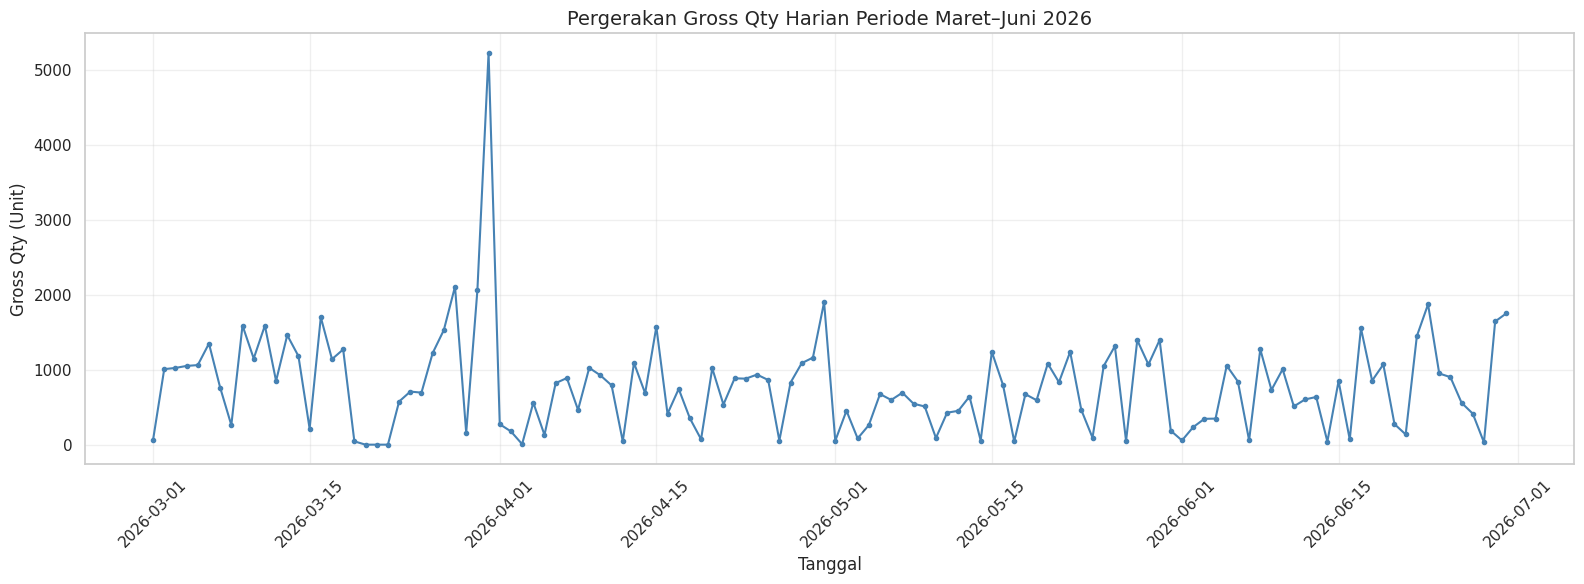

In [24]:
plt.figure(figsize=(16, 6))

plt.plot(
    daily_sales["Tanggal"],
    daily_sales["Gross Qty"],
    color="steelblue",
    linewidth=1.5,
    marker="o",
    markersize=3
)

plt.title("Pergerakan Gross Qty Harian Periode Maret–Juni 2026",
          fontsize=14)
plt.xlabel("Tanggal")
plt.ylabel("Gross Qty (Unit)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [25]:
print("Statistik Deskriptif Gross Qty Harian:")
display(daily_sales["Gross Qty"].describe())

print("\nNilai penjualan harian tertinggi:")
display(
    daily_sales.loc[
        daily_sales["Gross Qty"].idxmax()
    ]
)

print("\nNilai penjualan harian terendah:")
display(
    daily_sales.loc[
        daily_sales["Gross Qty"].idxmin()
    ]
)

Statistik Deskriptif Gross Qty Harian:


,Gross Qty
count,122.00
mean,782.82
std,664.27
min,0.00
25%,273.25
50%,738.00
75%,"1,080.25"
max,"5,234.00"



Nilai penjualan harian tertinggi:


,30
Tanggal,2026-03-31 00:00:00
Gross Qty,"5,234.00"



Nilai penjualan harian terendah:


,19
Tanggal,2026-03-20 00:00:00
Gross Qty,0.00


In [29]:
# Cell 21 — Analisis Gross Qty berdasarkan Hari

daily_sales["Nama_Hari"] = daily_sales["Tanggal"].dt.day_name()

# Mengubah nama hari ke bahasa Indonesia
nama_hari = {
    "Monday": "Senin",
    "Tuesday": "Selasa",
    "Wednesday": "Rabu",
    "Thursday": "Kamis",
    "Friday": "Jumat",
    "Saturday": "Sabtu",
    "Sunday": "Minggu"
}

daily_sales["Nama_Hari"] = daily_sales["Nama_Hari"].map(nama_hari)

urutan_hari = [
    "Senin", "Selasa", "Rabu", "Kamis",
    "Jumat", "Sabtu", "Minggu"
]

analisis_hari = (
    daily_sales
    .groupby("Nama_Hari")["Gross Qty"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .reindex(urutan_hari)
    .round(2)
)

display(analisis_hari)

,count,mean,median,std,min,max
Nama_Hari,,,,,,
Senin,18,"1,021.72","1,014.50",531.46,56.00,"2,060.00"
Selasa,18,"1,120.22",810.50,"1,128.72",69.00,"5,234.00"
Rabu,17,894.24,951.00,464.78,48.00,"1,591.00"
Kamis,17,775.12,851.00,490.59,44.00,"1,904.00"
Jumat,17,847.00,936.00,491.52,0.00,"1,531.00"
Sabtu,17,730.29,637.00,488.53,0.00,"2,112.00"
Minggu,18,97.56,77.50,69.85,0.00,261.00


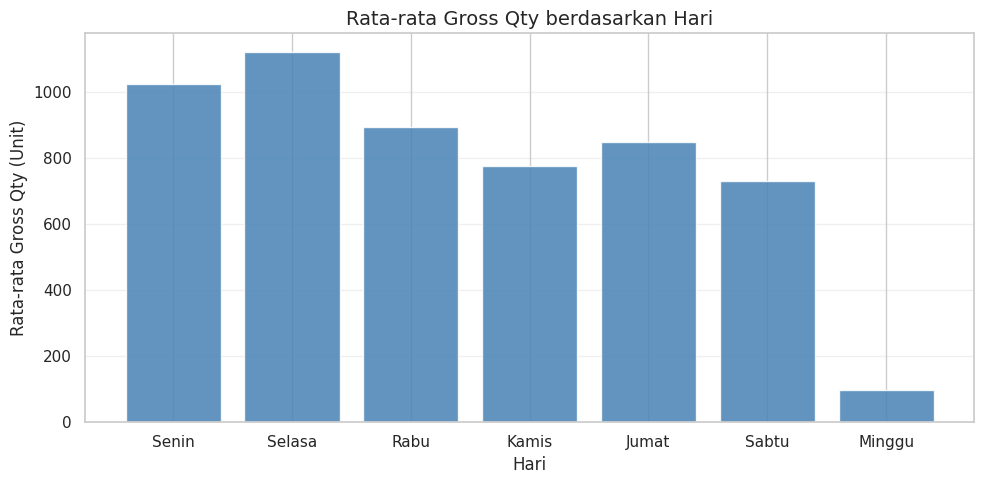

In [30]:
plt.figure(figsize=(10, 5))

plt.bar(
    analisis_hari.index,
    analisis_hari["mean"],
    color="steelblue",
    alpha=0.85
)

plt.title(
    "Rata-rata Gross Qty berdasarkan Hari",
    fontsize=14
)
plt.xlabel("Hari")
plt.ylabel("Rata-rata Gross Qty (Unit)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [31]:
tanggal_puncak = daily_sales.loc[
    daily_sales["Gross Qty"].idxmax(), "Tanggal"
]

transaksi_puncak = df_penjualan[
    df_penjualan["Tanggal"] == tanggal_puncak
].copy()

print("Tanggal dengan Gross Qty tertinggi:", tanggal_puncak)
print("Jumlah baris transaksi:", len(transaksi_puncak))
print("Total Gross Qty:", transaksi_puncak["Qty"].sum())

display(
    transaksi_puncak.sort_values(
        "Qty", ascending=False
    ).head(15)
)

Tanggal dengan Gross Qty tertinggi: 2026-03-31 00:00:00
Jumlah baris transaksi: 1259
Total Gross Qty: 5234


,Tanggal,Sales Invoice,Customer,Branch,Item Code,Item Name,Sub Brand,Qty,Harga,Total Harga,Retur,Diskon,Total,Jenis_Invoice
10698,2026-03-31,ACC-SINV-2026-07857,TOKO ELISHA - Jakarta,JABAR-JKT,1050203011,SLEEK ET LISSE Step 2 Cream Neutralizer 500 Ml,Straight System,60,89000,5340000,0,480600,4859400,Invoice Penjualan
10690,2026-03-31,ACC-SINV-2026-07857,TOKO ELISHA - Jakarta,JABAR-JKT,1010401032,IL Vasto Volume 20 Creme Peroxide 200 ML,Peroxide,60,56000,3360000,0,672000,2688000,Invoice Penjualan
10689,2026-03-31,ACC-SINV-2026-07857,TOKO ELISHA - Jakarta,JABAR-JKT,1010401034,IL VASTO Volume 20 Creme Peroxide 1000 ML,Peroxide,48,142000,6816000,0,613440,6202560,Invoice Penjualan
10692,2026-03-31,ACC-SINV-2026-07857,TOKO ELISHA - Jakarta,JABAR-JKT,1010401042,IL Vasto Volume 30 Creme Peroxide 200 ML,Peroxide,48,56000,2688000,0,537600,2150400,Invoice Penjualan
10027,2026-03-31,ACC-SINV-2026-07720,Toko Beauty Box- Manado,MND,1050203011,SLEEK ET LISSE Step 2 Cream Neutralizer 500 Ml,Straight System,36,80100,2883600,0,0,2883600,Invoice Penjualan
10601,2026-03-31,ACC-SINV-2026-07840,MEGAH JAYA TOKO- Surabaya,JATIM,1010401044,IL VASTO Volume 30 Creme Peroxide 1000 ML,Peroxide,36,142000,5112000,0,460080,4651920,Invoice Penjualan
10610,2026-03-31,ACC-SINV-2026-07840,MEGAH JAYA TOKO- Surabaya,JATIM,1050201011,Sleek Et Lisse Strong Curly Hair Step 1 & Step...,Straight System,36,80000,2880000,0,259200,2620800,Invoice Penjualan
10609,2026-03-31,ACC-SINV-2026-07840,MEGAH JAYA TOKO- Surabaya,JATIM,1050203011,SLEEK ET LISSE Step 2 Cream Neutralizer 500 Ml,Straight System,36,89000,3204000,0,288360,2915640,Invoice Penjualan
10621,2026-03-31,ACC-SINV-2026-07843,Toko harky- Jakarta,JABAR-JKT,1010401034,IL VASTO Volume 20 Creme Peroxide 1000 ML,Peroxide,36,142000,5112000,0,460080,4651920,Invoice Penjualan
10607,2026-03-31,ACC-SINV-2026-07840,MEGAH JAYA TOKO- Surabaya,JATIM,1050201021,Sleek Et Lisse Normal Curly Hair Step 1 & Step...,Straight System,36,80000,2880000,0,576000,2304000,Invoice Penjualan


In [32]:
# Mengurutkan tanggal berdasarkan Gross Qty tertinggi
top_10_penjualan = (
    daily_sales
    .sort_values("Gross Qty", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

print("10 Tanggal dengan Gross Qty Tertinggi:")
display(top_10_penjualan)

10 Tanggal dengan Gross Qty Tertinggi:


,Tanggal,Gross Qty,Nama_Hari
0,2026-03-31,"5,234.00",Selasa
1,2026-03-28,"2,112.00",Sabtu
2,2026-03-30,"2,060.00",Senin
3,2026-04-30,"1,904.00",Kamis
4,2026-06-23,"1,875.00",Selasa
5,2026-06-30,"1,754.00",Selasa
6,2026-03-16,"1,703.00",Senin
7,2026-06-29,"1,646.00",Senin
8,2026-03-09,"1,592.00",Senin
9,2026-03-11,"1,591.00",Rabu


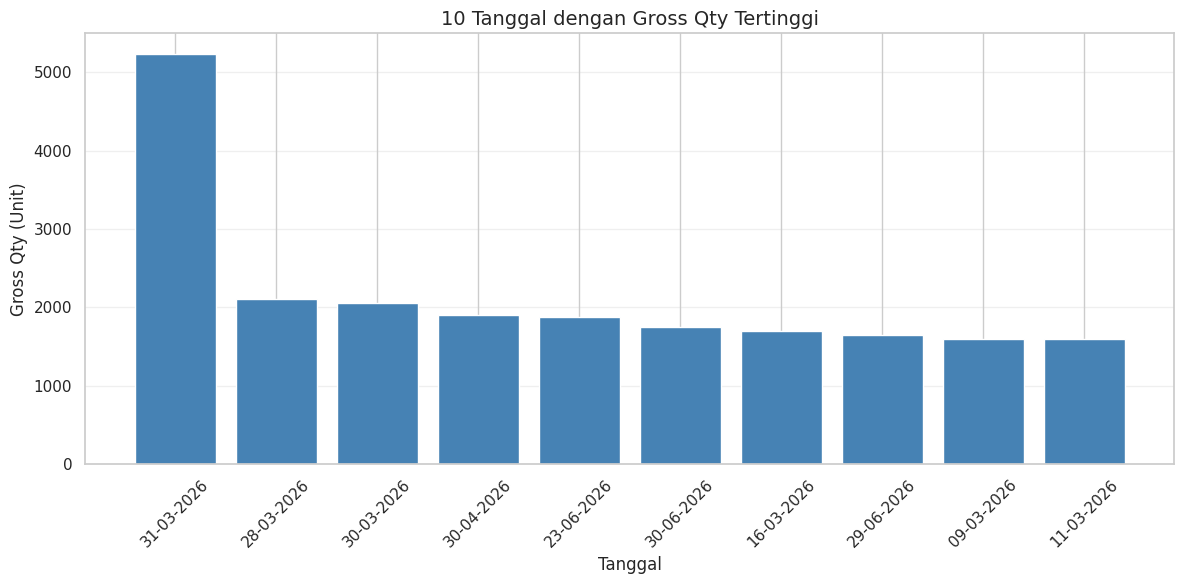

In [33]:
plt.figure(figsize=(12, 6))

plt.bar(
    top_10_penjualan["Tanggal"].dt.strftime("%d-%m-%Y"),
    top_10_penjualan["Gross Qty"],
    color="steelblue"
)

plt.title("10 Tanggal dengan Gross Qty Tertinggi", fontsize=14)
plt.xlabel("Tanggal")
plt.ylabel("Gross Qty (Unit)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

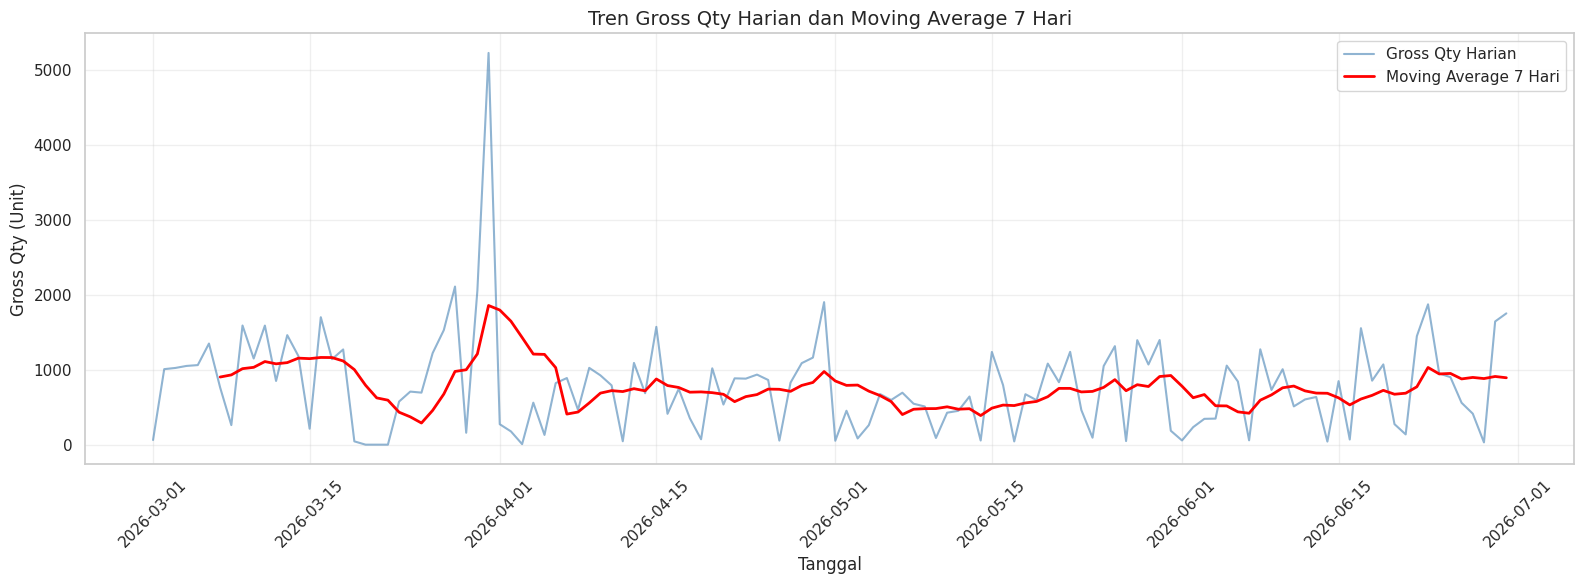

In [34]:
# Menghitung moving average 7 hari
daily_sales["MA_7"] = (
    daily_sales["Gross Qty"]
    .rolling(window=7)
    .mean()
)

plt.figure(figsize=(16, 6))

# Data Gross Qty harian
plt.plot(
    daily_sales["Tanggal"],
    daily_sales["Gross Qty"],
    label="Gross Qty Harian",
    color="steelblue",
    alpha=0.6
)

# Moving average 7 hari
plt.plot(
    daily_sales["Tanggal"],
    daily_sales["MA_7"],
    label="Moving Average 7 Hari",
    color="red",
    linewidth=2
)

plt.title(
    "Tren Gross Qty Harian dan Moving Average 7 Hari",
    fontsize=14
)
plt.xlabel("Tanggal")
plt.ylabel("Gross Qty (Unit)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [35]:
from statsmodels.tsa.stattools import adfuller, kpss
# Mengambil data Gross Qty sebagai time series
y = daily_sales["Gross Qty"]

# Uji Augmented Dickey-Fuller
hasil_adf = adfuller(y, autolag="AIC")

# Uji KPSS
hasil_kpss = kpss(y, regression="c", nlags="auto")

# Menampilkan hasil
print("HASIL UJI STASIONERITAS DATA ASLI")
print("=" * 45)

print("\nAugmented Dickey-Fuller (ADF)")
print(f"ADF Statistic : {hasil_adf[0]:.4f}")
print(f"p-value       : {hasil_adf[1]:.4f}")
print(f"Critical Value 1%  : {hasil_adf[4]['1%']:.4f}")
print(f"Critical Value 5%  : {hasil_adf[4]['5%']:.4f}")
print(f"Critical Value 10% : {hasil_adf[4]['10%']:.4f}")

print("\nKwiatkowski-Phillips-Schmidt-Shin (KPSS)")
print(f"KPSS Statistic : {hasil_kpss[0]:.4f}")
print(f"p-value        : {hasil_kpss[1]:.4f}")
print(f"Critical Value 1%  : {hasil_kpss[3]['1%']:.4f}")
print(f"Critical Value 5%  : {hasil_kpss[3]['5%']:.4f}")
print(f"Critical Value 10% : {hasil_kpss[3]['10%']:.4f}")

HASIL UJI STASIONERITAS DATA ASLI

Augmented Dickey-Fuller (ADF)
ADF Statistic : -9.4158
p-value       : 0.0000
Critical Value 1%  : -3.4856
Critical Value 5%  : -2.8857
Critical Value 10% : -2.5797

Kwiatkowski-Phillips-Schmidt-Shin (KPSS)
KPSS Statistic : 0.2158
p-value        : 0.1000
Critical Value 1%  : 0.7390
Critical Value 5%  : 0.4630
Critical Value 10% : 0.3470


/tmp/ipykernel_430/691312009.py:9: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  hasil_kpss = kpss(y, regression="c", nlags="auto")


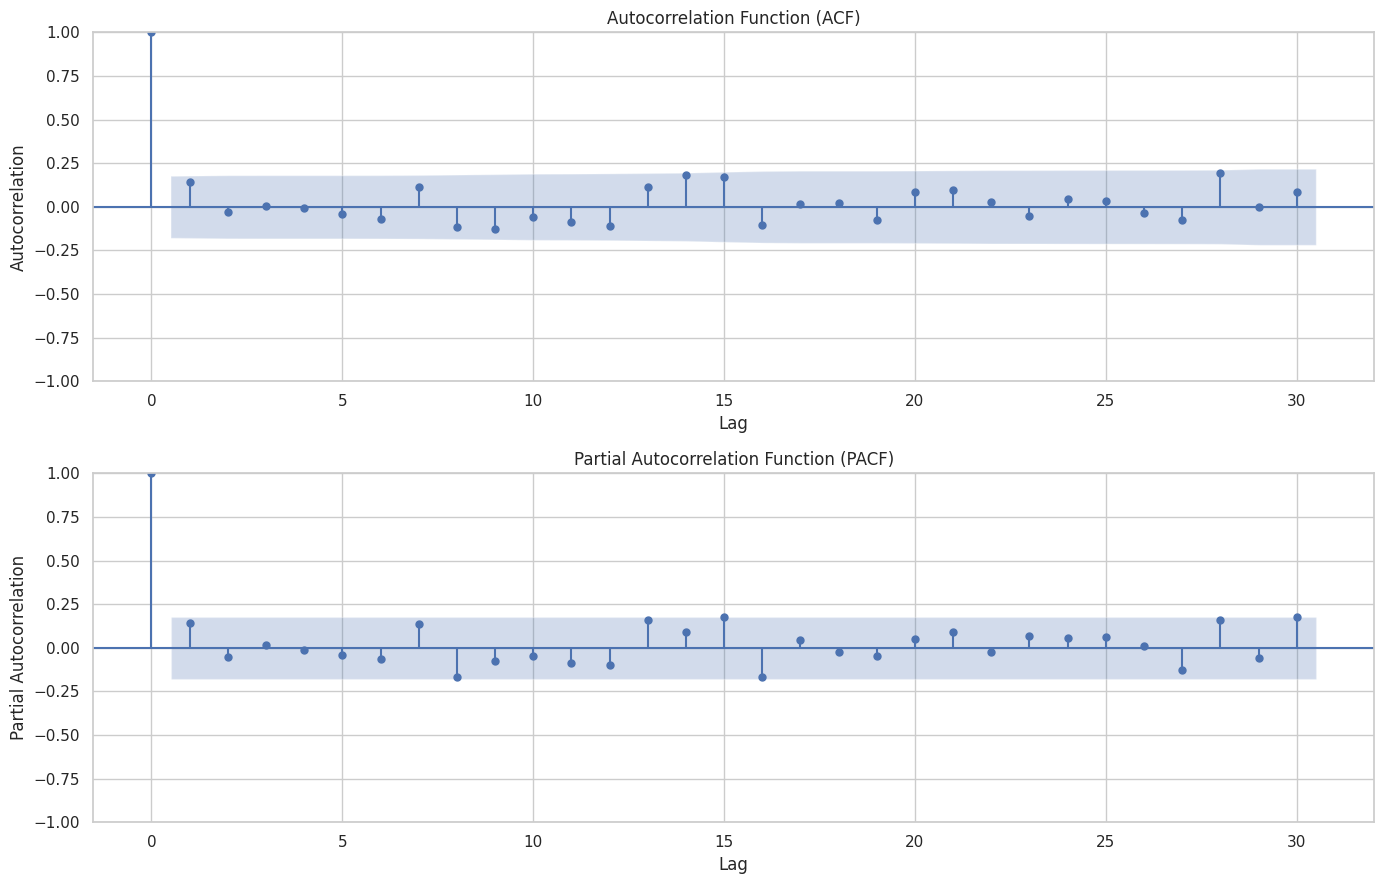

In [36]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Menyiapkan data time series
y = daily_sales["Gross Qty"]

# Membuat grafik ACF dan PACF
fig, axes = plt.subplots(2, 1, figsize=(14, 9))

# ACF untuk identifikasi kandidat q
plot_acf(
    y,
    lags=30,
    ax=axes[0],
    alpha=0.05
)
axes[0].set_title("Autocorrelation Function (ACF)")
axes[0].set_xlabel("Lag")
axes[0].set_ylabel("Autocorrelation")

# PACF untuk identifikasi kandidat p
plot_pacf(
    y,
    lags=30,
    ax=axes[1],
    method="ywm",
    alpha=0.05
)
axes[1].set_title("Partial Autocorrelation Function (PACF)")
axes[1].set_xlabel("Lag")
axes[1].set_ylabel("Partial Autocorrelation")

plt.tight_layout()
plt.show()

In [37]:
# Menentukan batas pembagian data
batas_train = int(len(daily_sales) * 0.8)

# Membagi data secara kronologis
train = daily_sales["Gross Qty"].iloc[:batas_train]
test = daily_sales["Gross Qty"].iloc[batas_train:]

print("PEMBAGIAN DATA TRAINING DAN TESTING")
print("=" * 45)

print(f"Total data       : {len(daily_sales)} hari")
print(f"Data training    : {len(train)} hari")
print(f"Data testing     : {len(test)} hari")

print(f"\nPeriode training : {daily_sales['Tanggal'].iloc[0].date()} "
      f"sampai {daily_sales['Tanggal'].iloc[batas_train-1].date()}")

print(f"Periode testing  : {daily_sales['Tanggal'].iloc[batas_train].date()} "
      f"sampai {daily_sales['Tanggal'].iloc[-1].date()}")

PEMBAGIAN DATA TRAINING DAN TESTING
Total data       : 122 hari
Data training    : 97 hari
Data testing     : 25 hari

Periode training : 2026-03-01 sampai 2026-06-05
Periode testing  : 2026-06-06 sampai 2026-06-30


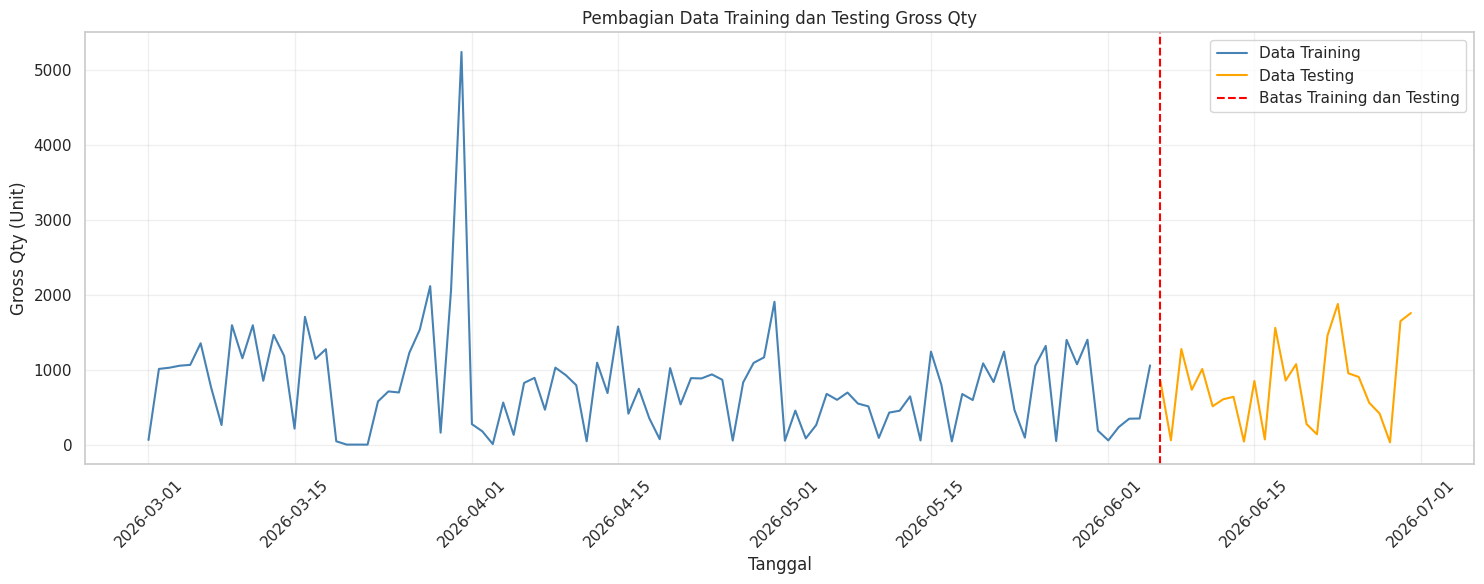

In [38]:
plt.figure(figsize=(15, 6))

plt.plot(
    daily_sales["Tanggal"].iloc[:batas_train],
    train,
    label="Data Training",
    color="steelblue"
)

plt.plot(
    daily_sales["Tanggal"].iloc[batas_train:],
    test,
    label="Data Testing",
    color="orange"
)

plt.axvline(
    daily_sales["Tanggal"].iloc[batas_train],
    color="red",
    linestyle="--",
    label="Batas Training dan Testing"
)

plt.title("Pembagian Data Training dan Testing Gross Qty")
plt.xlabel("Tanggal")
plt.ylabel("Gross Qty (Unit)")
plt.legend()
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [39]:
from statsmodels.tsa.arima.model import ARIMA

# Daftar kandidat parameter ARIMA (p, d, q)
kandidat_arima = [
    (0, 0, 0),
    (1, 0, 0),
    (0, 0, 1),
    (1, 0, 1),
    (2, 0, 0),
    (0, 0, 2),
    (2, 0, 1),
    (1, 0, 2),
    (2, 0, 2)
]

# Menyimpan hasil pemodelan
hasil_model = []

for order in kandidat_arima:
    try:
        model = ARIMA(
            train,
            order=order,
            trend="c"
        )

        hasil_fit = model.fit()

        hasil_model.append({
            "Model": f"ARIMA{order}",
            "p": order[0],
            "d": order[1],
            "q": order[2],
            "AIC": hasil_fit.aic,
            "BIC": hasil_fit.bic,
            "Konvergen": hasil_fit.mle_retvals.get(
                "converged", None
            )
        })

    except Exception as e:
        print(f"ARIMA{order} gagal: {e}")

# Mengubah hasil menjadi DataFrame
hasil_perbandingan = pd.DataFrame(hasil_model)

# Mengurutkan berdasarkan AIC terkecil
hasil_perbandingan = (
    hasil_perbandingan
    .sort_values("AIC")
    .reset_index(drop=True)
)

print("PERBANDINGAN KANDIDAT MODEL ARIMA")
display(hasil_perbandingan)

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


PERBANDINGAN KANDIDAT MODEL ARIMA


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


,Model,p,d,q,AIC,BIC,Konvergen
0,"ARIMA(1, 0, 1)",1,0,1,"1,545.68","1,555.98",True
1,"ARIMA(0, 0, 1)",0,0,1,"1,546.27","1,554.00",True
2,"ARIMA(1, 0, 0)",1,0,0,"1,546.41","1,554.14",True
3,"ARIMA(0, 0, 0)",0,0,0,"1,546.78","1,551.93",True
4,"ARIMA(2, 0, 1)",2,0,1,"1,547.13","1,560.00",True
5,"ARIMA(1, 0, 2)",1,0,2,"1,547.17","1,560.04",True
6,"ARIMA(2, 0, 0)",2,0,0,"1,548.28","1,558.58",True
7,"ARIMA(0, 0, 2)",0,0,2,"1,548.32","1,558.62",True
8,"ARIMA(2, 0, 2)",2,0,2,"1,549.18","1,564.63",False


In [40]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox

# Memodelkan dua kandidat terbaik
model_arima_101 = ARIMA(
    train,
    order=(1, 0, 1),
    trend="c"
).fit()

model_arima_000 = ARIMA(
    train,
    order=(0, 0, 0),
    trend="c"
).fit()

# Menyimpan model
model_arima = {
    "ARIMA(1,0,1)": model_arima_101,
    "ARIMA(0,0,0)": model_arima_000
}

print("Ringkasan Model ARIMA(1,0,1)")
print(model_arima_101.summary())

print("\nRingkasan Model ARIMA(0,0,0)")
print(model_arima_000.summary())

Ringkasan Model ARIMA(1,0,1)
                               SARIMAX Results                                
Dep. Variable:              Gross Qty   No. Observations:                   97
Model:                 ARIMA(1, 0, 1)   Log Likelihood                -768.839
Date:                Fri, 13 Nov 2026   AIC                           1545.677
Time:                        03:54:47   BIC                           1555.976
Sample:                             0   HQIC                          1549.842
                                 - 97                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        778.0063     94.740      8.212      0.000     592.319     963.693
ar.L1         -0.8184      0.156     -5.241      0.000      -1.125      -0.512
ma.L1          0.9645  

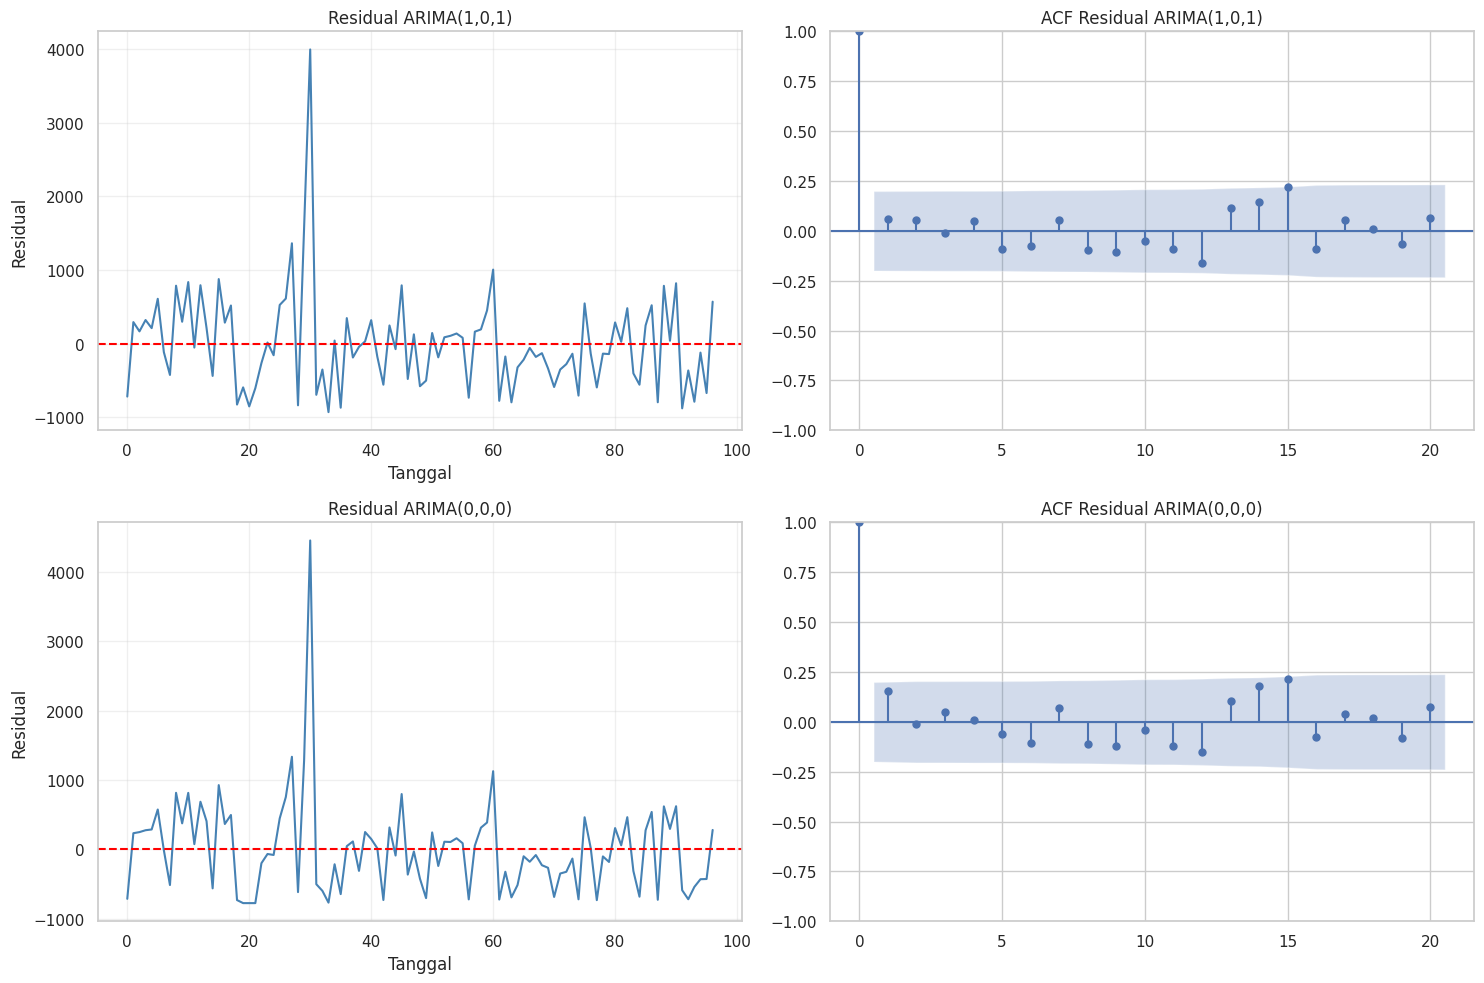

In [41]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for i, (nama, hasil_fit) in enumerate(model_arima.items()):

    residual = hasil_fit.resid

    # Grafik residual
    axes[i, 0].plot(
        residual.index,
        residual,
        color="steelblue"
    )
    axes[i, 0].axhline(0, color="red", linestyle="--")
    axes[i, 0].set_title(f"Residual {nama}")
    axes[i, 0].set_xlabel("Tanggal")
    axes[i, 0].set_ylabel("Residual")
    axes[i, 0].grid(alpha=0.3)

    # ACF residual
    plot_acf(
        residual,
        lags=20,
        ax=axes[i, 1],
        alpha=0.05
    )
    axes[i, 1].set_title(f"ACF Residual {nama}")

plt.tight_layout()
plt.show()

In [42]:
hasil_ljungbox = []

for nama, hasil_fit in model_arima.items():

    # Derajat kebebasan berdasarkan jumlah parameter AR dan MA
    model_df = hasil_fit.model_orders["ar"] + hasil_fit.model_orders["ma"]

    hasil_uji = acorr_ljungbox(
        hasil_fit.resid,
        lags=[7, 14],
        model_df=model_df,
        return_df=True
    )

    for lag, baris in hasil_uji.iterrows():
        hasil_ljungbox.append({
            "Model": nama,
            "Lag": lag,
            "Ljung-Box Statistic": baris["lb_stat"],
            "p-value": baris["lb_pvalue"]
        })

tabel_ljungbox = pd.DataFrame(hasil_ljungbox)

print("HASIL UJI LJUNG-BOX")
display(tabel_ljungbox)

HASIL UJI LJUNG-BOX


,Model,Lag,Ljung-Box Statistic,p-value
0,"ARIMA(1,0,1)",7,2.73,0.74
1,"ARIMA(1,0,1)",14,13.04,0.37
2,"ARIMA(0,0,0)",7,4.78,0.69
3,"ARIMA(0,0,0)",14,17.29,0.24


In [43]:
# Prediksi 25 hari ke depan menggunakan kedua model
prediksi_101 = model_arima_101.forecast(steps=len(test))
prediksi_000 = model_arima_000.forecast(steps=len(test))

# Membuat tabel perbandingan aktual dan prediksi
hasil_prediksi = pd.DataFrame({
    "Tanggal": daily_sales["Tanggal"].iloc[batas_train:].values,
    "Aktual": test.values,
    "Prediksi_ARIMA_101": prediksi_101.values,
    "Prediksi_ARIMA_000": prediksi_000.values
})

display(hasil_prediksi)

,Tanggal,Aktual,Prediksi_ARIMA_101,Prediksi_ARIMA_000
0,2026-06-06,843.00,"1,100.92",777.36
1,2026-06-07,58.00,513.73,777.36
2,2026-06-08,"1,274.00",994.30,777.36
3,2026-06-09,731.00,600.99,777.36
4,2026-06-10,"1,008.00",922.88,777.36
5,2026-06-11,511.00,659.44,777.36
6,2026-06-12,604.00,875.05,777.36
7,2026-06-13,637.00,698.59,777.36
8,2026-06-14,41.00,843.01,777.36
9,2026-06-15,849.00,724.81,777.36


In [44]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

def evaluasi_model(aktual, prediksi):

    mae = mean_absolute_error(aktual, prediksi)

    rmse = np.sqrt(
        mean_squared_error(aktual, prediksi)
    )

    wape = (
        np.sum(np.abs(aktual - prediksi))
        / np.sum(np.abs(aktual))
    ) * 100

    return mae, rmse, wape


# Menghitung evaluasi masing-masing model
hasil_evaluasi = []

for nama, kolom_prediksi in [
    ("ARIMA(1,0,1)", "Prediksi_ARIMA_101"),
    ("ARIMA(0,0,0)", "Prediksi_ARIMA_000")
]:

    mae, rmse, wape = evaluasi_model(
        hasil_prediksi["Aktual"],
        hasil_prediksi[kolom_prediksi]
    )

    hasil_evaluasi.append({
        "Model": nama,
        "MAE": mae,
        "RMSE": rmse,
        "WAPE (%)": wape
    })

tabel_evaluasi = pd.DataFrame(hasil_evaluasi)

print("HASIL EVALUASI MODEL ARIMA")
display(tabel_evaluasi)

HASIL EVALUASI MODEL ARIMA


,Model,MAE,RMSE,WAPE (%)
0,"ARIMA(1,0,1)",437.55,539.91,54.42
1,"ARIMA(0,0,0)",447.71,547.93,55.68


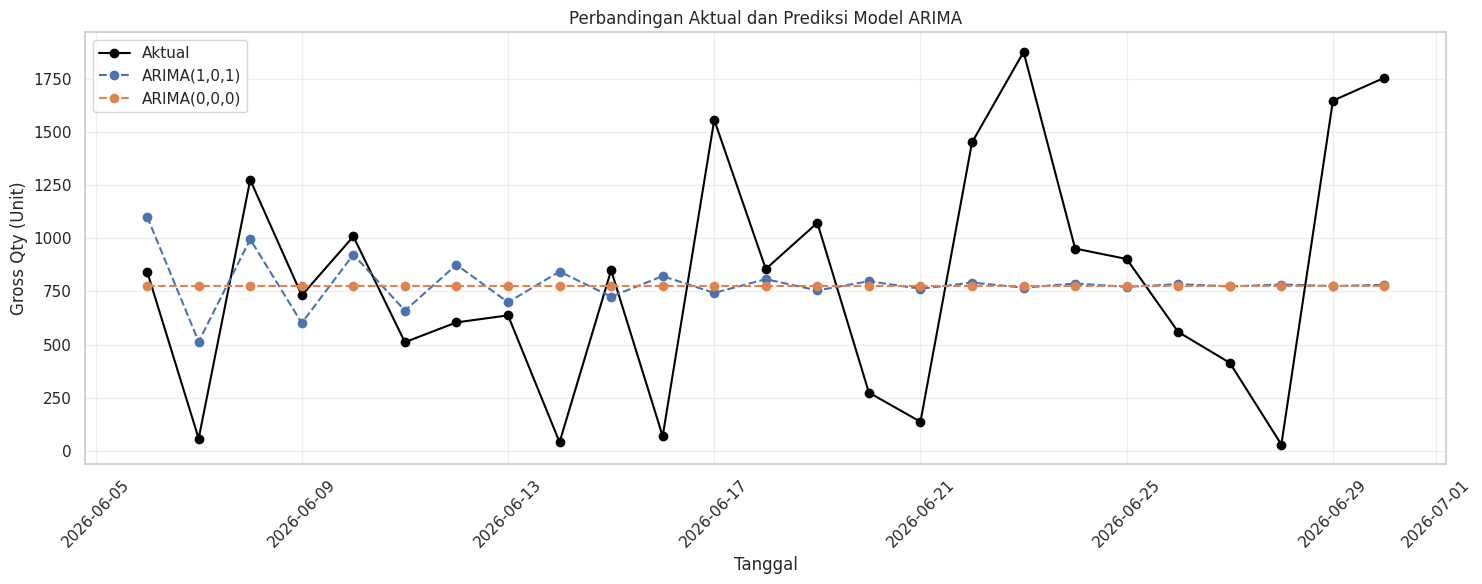

In [45]:
plt.figure(figsize=(15, 6))

plt.plot(
    hasil_prediksi["Tanggal"],
    hasil_prediksi["Aktual"],
    marker="o",
    label="Aktual",
    color="black"
)

plt.plot(
    hasil_prediksi["Tanggal"],
    hasil_prediksi["Prediksi_ARIMA_101"],
    linestyle="--",
    marker="o",
    label="ARIMA(1,0,1)"
)

plt.plot(
    hasil_prediksi["Tanggal"],
    hasil_prediksi["Prediksi_ARIMA_000"],
    linestyle="--",
    marker="o",
    label="ARIMA(0,0,0)"
)

plt.title("Perbandingan Aktual dan Prediksi Model ARIMA")
plt.xlabel("Tanggal")
plt.ylabel("Gross Qty (Unit)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [46]:
# Fungsi untuk membuat fitur berdasarkan riwayat Gross Qty
def buat_fitur(history, tanggal):

    fitur = {
        "Lag_1": history[-1],
        "Lag_2": history[-2],
        "Lag_3": history[-3],
        "Lag_7": history[-7],
        "Lag_14": history[-14],

        "Rolling_Mean_7": np.mean(history[-7:]),
        "Rolling_Mean_14": np.mean(history[-14:]),

        "Day_of_Week": tanggal.dayofweek,
        "Day": tanggal.day,
        "Month": tanggal.month,
        "Is_Weekend": int(tanggal.dayofweek >= 5)
    }

    return fitur


# Membuat dataset supervised dari data training
data_supervised = []

nilai_train = train.tolist()
tanggal_train = daily_sales["Tanggal"].iloc[:batas_train]

for i in range(14, len(train)):

    history = nilai_train[:i]
    tanggal = tanggal_train.iloc[i]

    fitur = buat_fitur(history, tanggal)

    fitur["Target"] = nilai_train[i]

    data_supervised.append(fitur)

df_supervised = pd.DataFrame(data_supervised)

# Memisahkan fitur dan target
X_train_xgb = df_supervised.drop(columns="Target")
y_train_xgb = df_supervised["Target"]

print("Bentuk dataset supervised:", df_supervised.shape)
print("Jumlah fitur:", X_train_xgb.shape[1])
print("Jumlah data training XGBoost:", len(X_train_xgb))

display(df_supervised.head())

Bentuk dataset supervised: (83, 12)
Jumlah fitur: 11
Jumlah data training XGBoost: 83


,Lag_1,Lag_2,Lag_3,Lag_7,Lag_14,Rolling_Mean_7,Rolling_Mean_14,Day_of_Week,Day,Month,Is_Weekend,Target
0,"1,183.00","1,463.00",851.00,261.00,62.00,"1,156.00","1,029.79",6,15,3,1,213.00
1,213.00,"1,183.00","1,463.00","1,592.00","1,009.00","1,149.14","1,040.57",0,16,3,0,"1,703.00"
2,"1,703.00",213.00,"1,183.00","1,151.00","1,025.00","1,165.00","1,090.14",1,17,3,0,"1,142.00"
3,"1,142.00","1,703.00",213.00,"1,591.00","1,052.00","1,163.71","1,098.50",2,18,3,0,"1,272.00"
4,"1,272.00","1,142.00","1,703.00",851.00,"1,063.00","1,118.14","1,114.21",3,19,3,0,44.00


In [47]:
from xgboost import XGBRegressor

# Inisialisasi model XGBoost
model_xgb = XGBRegressor(
    n_estimators=200,
    max_depth=2,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    reg_lambda=5,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# Melatih model
model_xgb.fit(
    X_train_xgb,
    y_train_xgb
)

print("Model XGBoost berhasil dilatih.")

Model XGBoost berhasil dilatih.


In [48]:
# Menyiapkan riwayat Gross Qty dari data training
history = train.tolist()

prediksi_xgb = []

# Melakukan prediksi untuk setiap tanggal testing
for tanggal in daily_sales["Tanggal"].iloc[batas_train:]:

    # Membuat fitur berdasarkan riwayat data
    fitur = buat_fitur(history, tanggal)

    # Mengubah fitur menjadi DataFrame
    X_next = pd.DataFrame([fitur])

    # Prediksi satu hari ke depan
    prediksi = model_xgb.predict(X_next)[0]

    # Membatasi prediksi agar tidak negatif
    prediksi = max(0, prediksi)

    prediksi_xgb.append(prediksi)

    # Memasukkan hasil prediksi ke riwayat
    history.append(prediksi)


# Membuat tabel hasil prediksi
hasil_prediksi_xgb = pd.DataFrame({
    "Tanggal": daily_sales["Tanggal"].iloc[batas_train:].values,
    "Aktual": test.values,
    "Prediksi_XGBoost": prediksi_xgb
})

display(hasil_prediksi_xgb)

,Tanggal,Aktual,Prediksi_XGBoost
0,2026-06-06,843.00,586.26
1,2026-06-07,58.00,281.73
2,2026-06-08,"1,274.00",706.60
3,2026-06-09,731.00,802.00
4,2026-06-10,"1,008.00",723.71
5,2026-06-11,511.00,806.98
6,2026-06-12,604.00,660.29
7,2026-06-13,637.00,744.21
8,2026-06-14,41.00,336.23
9,2026-06-15,849.00,745.07


In [49]:
mae_xgb, rmse_xgb, wape_xgb = evaluasi_model(
    hasil_prediksi_xgb["Aktual"],
    hasil_prediksi_xgb["Prediksi_XGBoost"]
)

tabel_evaluasi_xgb = pd.DataFrame({
    "Model": ["XGBoost"],
    "MAE": [mae_xgb],
    "RMSE": [rmse_xgb],
    "WAPE (%)": [wape_xgb]
})

display(tabel_evaluasi_xgb)

,Model,MAE,RMSE,WAPE (%)
0,XGBoost,352.81,438.76,43.88


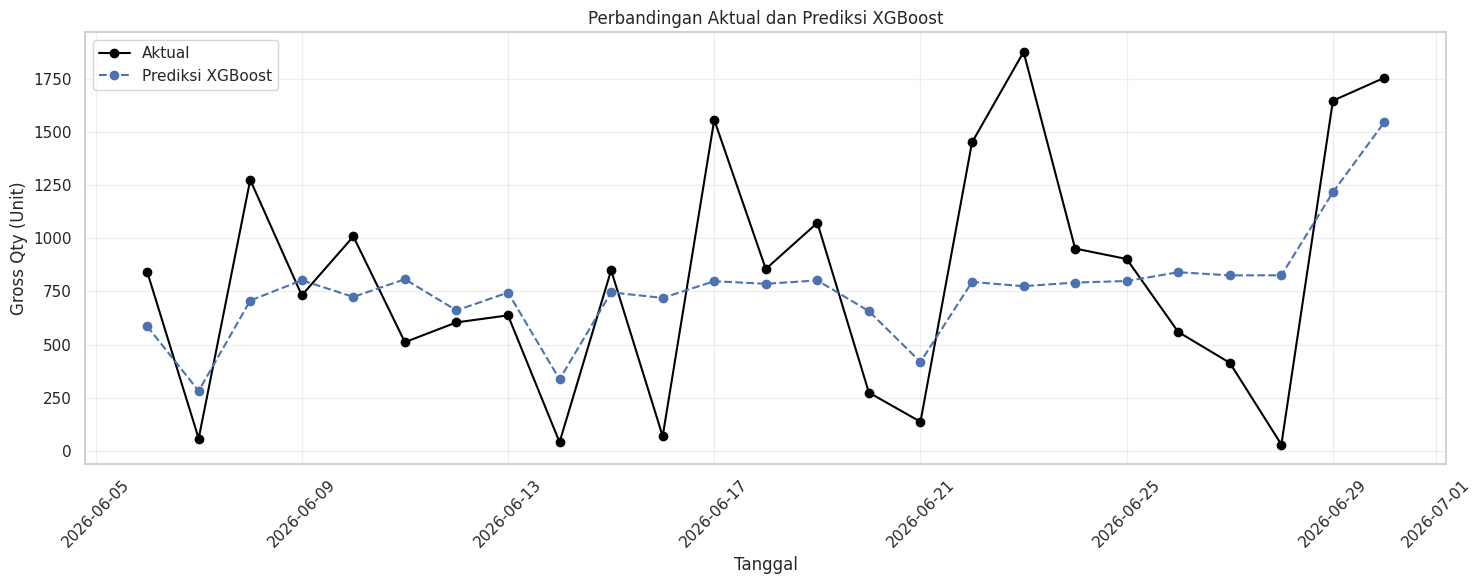

In [50]:
plt.figure(figsize=(15, 6))

plt.plot(
    hasil_prediksi_xgb["Tanggal"],
    hasil_prediksi_xgb["Aktual"],
    marker="o",
    label="Aktual",
    color="black"
)

plt.plot(
    hasil_prediksi_xgb["Tanggal"],
    hasil_prediksi_xgb["Prediksi_XGBoost"],
    marker="o",
    linestyle="--",
    label="Prediksi XGBoost"
)

plt.title("Perbandingan Aktual dan Prediksi XGBoost")
plt.xlabel("Tanggal")
plt.ylabel("Gross Qty (Unit)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

,Fitur,Importance
8,Day,0.18
9,Month,0.12
4,Lag_14,0.11
7,Day_of_Week,0.10
5,Rolling_Mean_7,0.08
2,Lag_3,0.08
10,Is_Weekend,0.07
3,Lag_7,0.07
0,Lag_1,0.07
6,Rolling_Mean_14,0.06


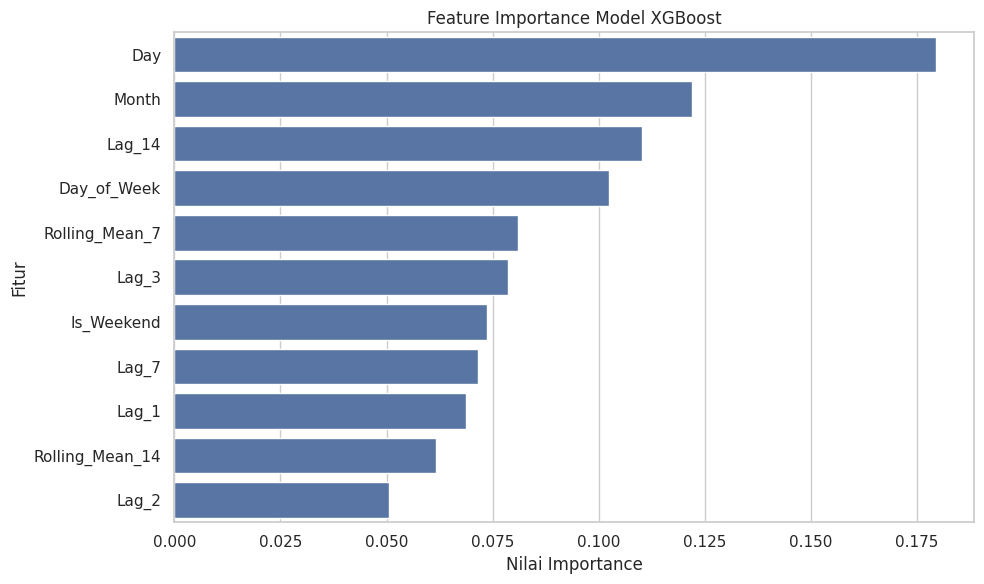

In [51]:
# Mengambil nilai feature importance
importance = pd.DataFrame({
    "Fitur": X_train_xgb.columns,
    "Importance": model_xgb.feature_importances_
})

# Mengurutkan fitur berdasarkan tingkat kepentingan
importance = importance.sort_values(
    by="Importance",
    ascending=False
)

display(importance)

# Visualisasi feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance,
    x="Importance",
    y="Fitur"
)

plt.title("Feature Importance Model XGBoost")
plt.xlabel("Nilai Importance")
plt.ylabel("Fitur")
plt.tight_layout()
plt.show()

In [52]:
# Prediksi menggunakan nilai aktual satu hari sebelumnya
prediksi_naive = daily_sales["Gross Qty"].iloc[
    batas_train - 1 : -1
].values

# Membuat tabel hasil prediksi baseline
hasil_naive = pd.DataFrame({
    "Tanggal": daily_sales["Tanggal"].iloc[batas_train:].values,
    "Aktual": test.values,
    "Prediksi_Naive": prediksi_naive
})

# Menghitung evaluasi
mae_naive, rmse_naive, wape_naive = evaluasi_model(
    hasil_naive["Aktual"],
    hasil_naive["Prediksi_Naive"]
)

# Menampilkan hasil
evaluasi_naive = pd.DataFrame({
    "Model": ["Naive Forecast"],
    "MAE": [mae_naive],
    "RMSE": [rmse_naive],
    "WAPE (%)": [wape_naive]
})

display(hasil_naive)
display(evaluasi_naive)

,Tanggal,Aktual,Prediksi_Naive
0,2026-06-06,843.00,"1,056.00"
1,2026-06-07,58.00,843.00
2,2026-06-08,"1,274.00",58.00
3,2026-06-09,731.00,"1,274.00"
4,2026-06-10,"1,008.00",731.00
5,2026-06-11,511.00,"1,008.00"
6,2026-06-12,604.00,511.00
7,2026-06-13,637.00,604.00
8,2026-06-14,41.00,637.00
9,2026-06-15,849.00,41.00


,Model,MAE,RMSE,WAPE (%)
0,Naive Forecast,579.52,733.77,72.08


In [53]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Membuat tabel perbandingan hasil evaluasi
perbandingan_model = pd.DataFrame({
    "Model": ["ARIMA(1,0,1)", "XGBoost"],
    "MAE": [437.55, 352.81],
    "RMSE": [539.91, 438.76],
    "WAPE (%)": [54.42, 43.88]
})

print("PERBANDINGAN HASIL EVALUASI MODEL")
print("=" * 60)

display(perbandingan_model)

PERBANDINGAN HASIL EVALUASI MODEL


,Model,MAE,RMSE,WAPE (%)
0,"ARIMA(1,0,1)",437.55,539.91,54.42
1,XGBoost,352.81,438.76,43.88


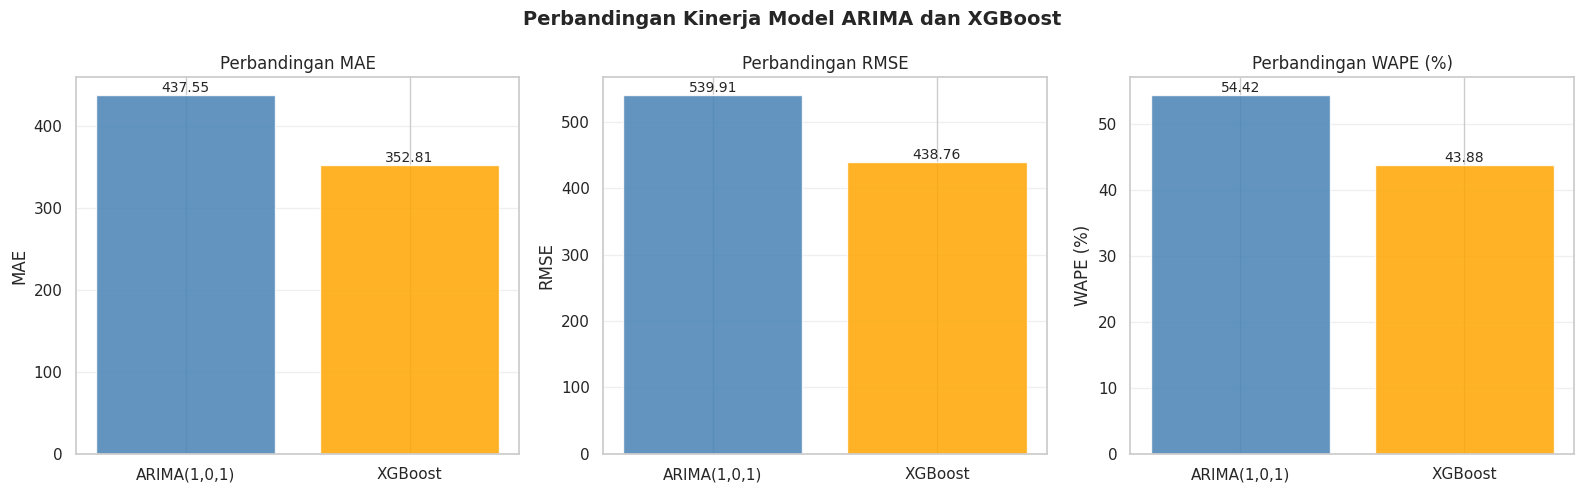

In [54]:
# Menentukan metrik evaluasi
metrik = ["MAE", "RMSE", "WAPE (%)"]

# Membuat visualisasi
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, kolom in enumerate(metrik):
    bars = axes[i].bar(
        perbandingan_model["Model"],
        perbandingan_model[kolom],
        color=["steelblue", "orange"],
        alpha=0.85
    )

    axes[i].set_title(f"Perbandingan {kolom}", fontsize=12)
    axes[i].set_ylabel(kolom)
    axes[i].grid(axis="y", alpha=0.3)

    # Menampilkan nilai di atas batang
    for bar in bars:
        tinggi = bar.get_height()
        axes[i].text(
            bar.get_x() + bar.get_width() / 2,
            tinggi,
            f"{tinggi:.2f}",
            ha="center",
            va="bottom",
            fontsize=10
        )

plt.suptitle(
    "Perbandingan Kinerja Model ARIMA dan XGBoost",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

,Tanggal,Aktual,Prediksi_ARIMA,Prediksi_XGBoost
0,2026-06-06,843.00,"1,100.92",586.26
1,2026-06-07,58.00,513.73,281.73
2,2026-06-08,"1,274.00",994.30,706.60
3,2026-06-09,731.00,600.99,802.00
4,2026-06-10,"1,008.00",922.88,723.71
5,2026-06-11,511.00,659.44,806.98
6,2026-06-12,604.00,875.05,660.29
7,2026-06-13,637.00,698.59,744.21
8,2026-06-14,41.00,843.01,336.23
9,2026-06-15,849.00,724.81,745.07


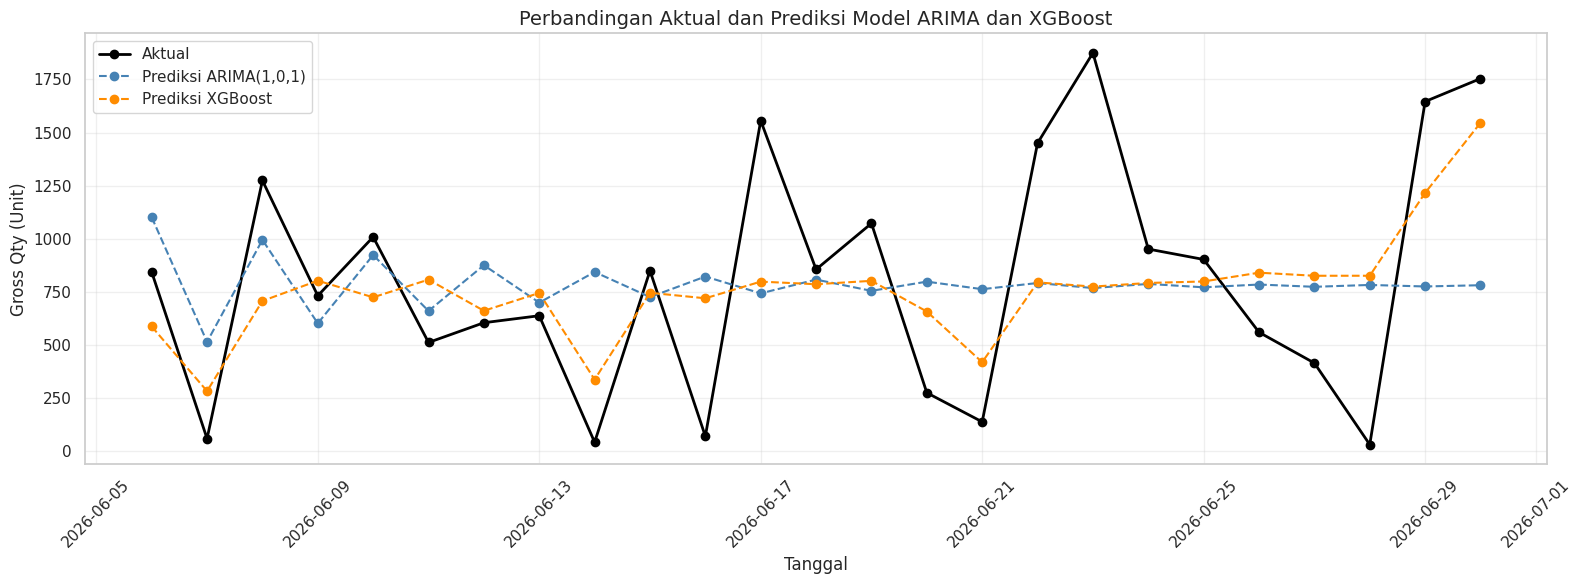

In [55]:
# Membuat DataFrame perbandingan prediksi dengan variabel yang ada di kernel
hasil_perbandingan = pd.DataFrame({
    "Tanggal": hasil_prediksi["Tanggal"],
    "Aktual": test.values,
    "Prediksi_ARIMA": prediksi_101.values,
    "Prediksi_XGBoost": np.array(prediksi_xgb).flatten()
})

display(hasil_perbandingan)

# Visualisasi aktual dan prediksi
plt.figure(figsize=(16, 6))

plt.plot(
    hasil_perbandingan["Tanggal"],
    hasil_perbandingan["Aktual"],
    label="Aktual",
    color="black",
    marker="o",
    linewidth=2
)

plt.plot(
    hasil_perbandingan["Tanggal"],
    hasil_perbandingan["Prediksi_ARIMA"],
    label="Prediksi ARIMA(1,0,1)",
    color="steelblue",
    marker="o",
    linestyle="--"
)

plt.plot(
    hasil_perbandingan["Tanggal"],
    hasil_perbandingan["Prediksi_XGBoost"],
    label="Prediksi XGBoost",
    color="darkorange",
    marker="o",
    linestyle="--"
)

plt.title(
    "Perbandingan Aktual dan Prediksi Model ARIMA dan XGBoost",
    fontsize=14
)
plt.xlabel("Tanggal")
plt.ylabel("Gross Qty (Unit)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [56]:
# Menentukan model dengan nilai kesalahan terendah
model_terbaik = perbandingan_model.loc[
    perbandingan_model["WAPE (%)"].idxmin()
]

print("MODEL TERBAIK BERDASARKAN WAPE")
print("=" * 40)
print("Model :", model_terbaik["Model"])
print("MAE   :", model_terbaik["MAE"])
print("RMSE  :", model_terbaik["RMSE"])
print("WAPE  :", model_terbaik["WAPE (%)"], "%")

MODEL TERBAIK BERDASARKAN WAPE
Model : XGBoost
MAE   : 352.81
RMSE  : 438.76
WAPE  : 43.88 %


In [57]:
# ============================================================
# 1. PERSIAPAN DAN PEMERIKSAAN DATA HISTORIS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from xgboost import XGBRegressor
from IPython.display import display

# Salin data agar data sebelumnya tidak berubah
forecast_data = daily_sales.copy()

# Pastikan tipe data tanggal sesuai
forecast_data["Tanggal"] = pd.to_datetime(forecast_data["Tanggal"])

# Urutkan berdasarkan tanggal
forecast_data = (
    forecast_data
    .sort_values("Tanggal")
    .reset_index(drop=True)
)

# Pastikan kolom target tersedia
if "Gross Qty" not in forecast_data.columns:
    raise ValueError("Kolom 'Gross Qty' tidak ditemukan.")

# Pastikan tidak ada nilai kosong
if forecast_data[["Tanggal", "Gross Qty"]].isna().any().any():
    raise ValueError("Masih terdapat nilai kosong pada data historis.")

# Pastikan tidak ada tanggal ganda
if forecast_data["Tanggal"].duplicated().any():
    raise ValueError("Terdapat tanggal yang berulang pada data harian.")

# Pastikan data mencakup 122 hari
if len(forecast_data) != 122:
    raise ValueError(
        f"Jumlah data historis seharusnya 122 hari, "
        f"tetapi ditemukan {len(forecast_data)} hari."
    )

# Pastikan periode data sesuai
print("Periode data historis:",
      forecast_data["Tanggal"].min().date(),
      "sampai",
      forecast_data["Tanggal"].max().date())

print("Jumlah observasi:", len(forecast_data))
print("Total Gross Qty:", forecast_data["Gross Qty"].sum())

display(forecast_data.head())
display(forecast_data.tail())

Periode data historis: 2026-03-01 sampai 2026-06-30
Jumlah observasi: 122
Total Gross Qty: 95504.0


,Tanggal,Gross Qty,Nama_Hari,MA_7
0,2026-03-01,62.00,Minggu,NaN
1,2026-03-02,"1,009.00",Senin,NaN
2,2026-03-03,"1,025.00",Selasa,NaN
3,2026-03-04,"1,052.00",Rabu,NaN
4,2026-03-05,"1,063.00",Kamis,NaN


,Tanggal,Gross Qty,Nama_Hari,MA_7
117,2026-06-26,559.00,Jumat,878.29
118,2026-06-27,414.00,Sabtu,898.29
119,2026-06-28,30.00,Minggu,883.00
120,2026-06-29,"1,646.00",Senin,911.00
121,2026-06-30,"1,754.00",Selasa,893.71


In [58]:
# ============================================================
# 2. PEMBENTUKAN FITUR
# ============================================================

def create_features(history, target_date):
    """
    Membentuk fitur berdasarkan data historis sebelum target_date.
    """

    history = np.asarray(history, dtype=float)

    if len(history) < 14:
        raise ValueError("Minimal diperlukan 14 observasi historis.")

    features = {
        "Lag_1": history[-1],
        "Lag_2": history[-2],
        "Lag_3": history[-3],
        "Lag_7": history[-7],
        "Lag_14": history[-14],

        "Rolling_Mean_7": np.mean(history[-7:]),
        "Rolling_Mean_14": np.mean(history[-14:]),

        "Day_of_Week": target_date.dayofweek,
        "Day": target_date.day,
        "Month": target_date.month,
        "Is_Weekend": int(target_date.dayofweek >= 5)
    }

    return features


# Menyimpan seluruh kuantitas penjualan historis
historical_values = forecast_data["Gross Qty"].astype(float).values

# Membentuk data supervised learning
feature_rows = []
target_values = []

for i in range(14, len(historical_values)):

    target_date = forecast_data.loc[i, "Tanggal"]

    features = create_features(
        historical_values[:i],
        target_date
    )

    feature_rows.append(features)
    target_values.append(historical_values[i])


# Membentuk DataFrame fitur dan target
X_full = pd.DataFrame(feature_rows)
y_full = pd.Series(target_values, name="Gross Qty")

print("Dimensi fitur:", X_full.shape)
print("Jumlah target:", len(y_full))

display(X_full.head())
display(y_full.head())

Dimensi fitur: (108, 11)
Jumlah target: 108


,Lag_1,Lag_2,Lag_3,Lag_7,Lag_14,Rolling_Mean_7,Rolling_Mean_14,Day_of_Week,Day,Month,Is_Weekend
0,"1,183.00","1,463.00",851.00,261.00,62.00,"1,156.00","1,029.79",6,15,3,1
1,213.00,"1,183.00","1,463.00","1,592.00","1,009.00","1,149.14","1,040.57",0,16,3,0
2,"1,703.00",213.00,"1,183.00","1,151.00","1,025.00","1,165.00","1,090.14",1,17,3,0
3,"1,142.00","1,703.00",213.00,"1,591.00","1,052.00","1,163.71","1,098.50",2,18,3,0
4,"1,272.00","1,142.00","1,703.00",851.00,"1,063.00","1,118.14","1,114.21",3,19,3,0


,Gross Qty
0,213.00
1,"1,703.00"
2,"1,142.00"
3,"1,272.00"
4,44.00


In [59]:
# ============================================================
# 3. PELATIHAN ULANG MODEL XGBOOST
# ============================================================

model_xgb_final = XGBRegressor(
    n_estimators=200,
    max_depth=2,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    reg_lambda=5,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# Melatih model menggunakan seluruh data historis
model_xgb_final.fit(X_full, y_full)

print("Pelatihan ulang model XGBoost berhasil.")
print("Jumlah data pelatihan:", len(X_full))
print("Jumlah fitur:", X_full.shape[1])

Pelatihan ulang model XGBoost berhasil.
Jumlah data pelatihan: 108
Jumlah fitur: 11


In [60]:
# ============================================================
# 4. RECURSIVE FORECASTING 30 HARI
# ============================================================

# Menentukan tanggal awal peramalan
last_date = forecast_data["Tanggal"].max()

forecast_start = last_date + pd.Timedelta(days=1)

# Menentukan jumlah hari peramalan
forecast_horizon = 30

# Menyimpan seluruh nilai historis
recursive_history = list(historical_values)

# Menyimpan hasil peramalan
forecast_results = []

for step in range(forecast_horizon):

    # Menentukan tanggal yang akan diprediksi
    target_date = forecast_start + pd.Timedelta(days=step)

    # Membentuk fitur berdasarkan riwayat terbaru
    features = create_features(
        recursive_history,
        target_date
    )

    # Mengubah fitur menjadi DataFrame
    X_future = pd.DataFrame([features])

    # Melakukan prediksi
    prediction = model_xgb_final.predict(X_future)[0]

    # Kuantitas penjualan tidak mungkin bernilai negatif
    prediction = max(0, prediction)

    # Menyimpan hasil prediksi
    forecast_results.append({
        "Tanggal": target_date,
        "Prediksi_Gross_Qty": prediction
    })

    # Memasukkan prediksi ke riwayat
    # untuk digunakan pada langkah berikutnya
    recursive_history.append(prediction)


# Membentuk DataFrame hasil peramalan
forecast_df = pd.DataFrame(forecast_results)

# Membuat kolom pembulatan untuk penyajian kuantitas
forecast_df["Prediksi_Gross_Qty_Bulat"] = (
    forecast_df["Prediksi_Gross_Qty"].round().astype(int)
)

print("Periode peramalan:",
      forecast_df["Tanggal"].min().date(),
      "sampai",
      forecast_df["Tanggal"].max().date())

print("Jumlah hari yang diramalkan:", len(forecast_df))

display(forecast_df)

Periode peramalan: 2026-07-01 sampai 2026-07-30
Jumlah hari yang diramalkan: 30


,Tanggal,Prediksi_Gross_Qty,Prediksi_Gross_Qty_Bulat
0,2026-07-01,535.40,535
1,2026-07-02,318.77,319
2,2026-07-03,395.92,396
3,2026-07-04,395.24,395
4,2026-07-05,86.86,87
5,2026-07-06,735.27,735
6,2026-07-07,700.80,701
7,2026-07-08,797.00,797
8,2026-07-09,779.21,779
9,2026-07-10,787.87,788


In [61]:
  # ============================================================
# 5. RINGKASAN HASIL PERAMALAN
# ============================================================

forecast_summary = pd.DataFrame({
    "Keterangan": [
        "Jumlah hari peramalan",
        "Total prediksi Gross Qty",
        "Rata-rata prediksi harian",
        "Prediksi tertinggi",
        "Prediksi terendah"
    ],

    "Nilai": [
        len(forecast_df),
        forecast_df["Prediksi_Gross_Qty"].sum(),
        forecast_df["Prediksi_Gross_Qty"].mean(),
        forecast_df["Prediksi_Gross_Qty"].max(),
        forecast_df["Prediksi_Gross_Qty"].min()
    ]
})

display(forecast_summary.round(2))

,Keterangan,Nilai
0,Jumlah hari peramalan,30.00
1,Total prediksi Gross Qty,"21,645.23"
2,Rata-rata prediksi harian,721.51
3,Prediksi tertinggi,"1,575.35"
4,Prediksi terendah,86.86


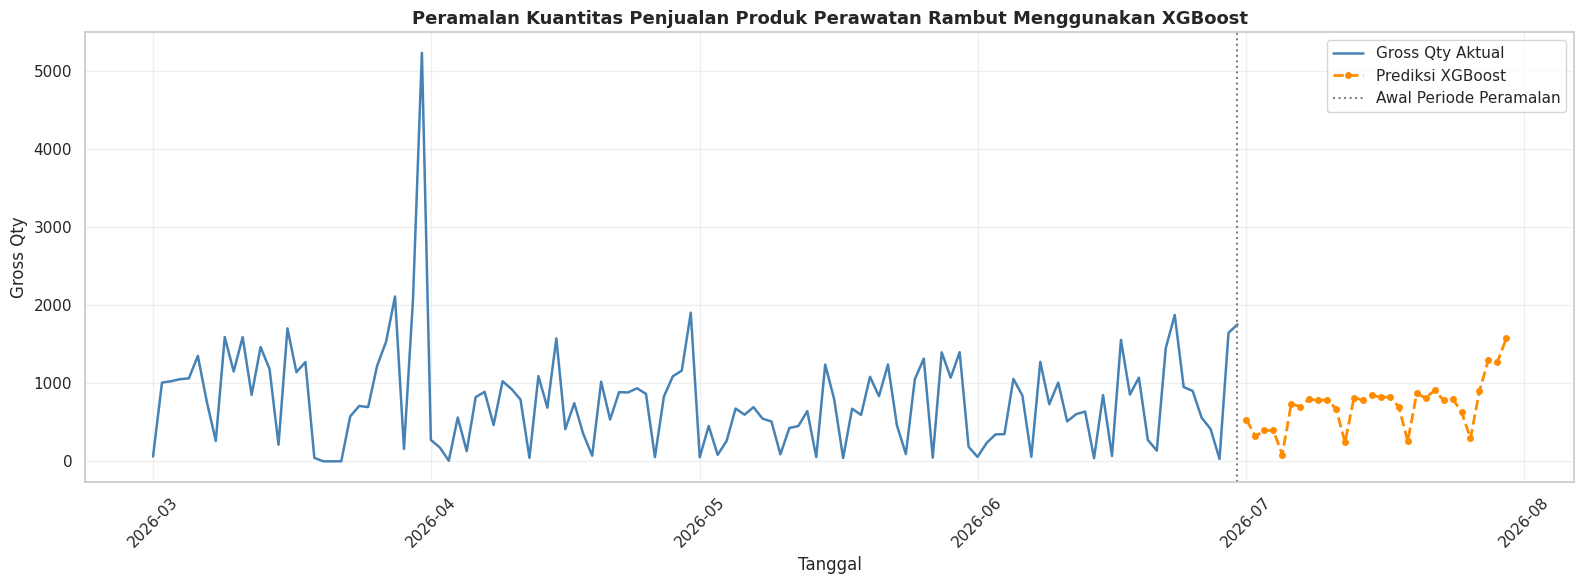

In [62]:
# ============================================================
# 6. VISUALISASI HASIL PERAMALAN
# ============================================================

plt.figure(figsize=(16, 6))

# Data historis
plt.plot(
    forecast_data["Tanggal"],
    forecast_data["Gross Qty"],
    label="Gross Qty Aktual",
    color="steelblue",
    linewidth=1.8
)

# Data hasil peramalan
plt.plot(
    forecast_df["Tanggal"],
    forecast_df["Prediksi_Gross_Qty"],
    label="Prediksi XGBoost",
    color="darkorange",
    linewidth=2,
    linestyle="--",
    marker="o",
    markersize=4
)

# Garis pemisah periode historis dan peramalan
plt.axvline(
    last_date,
    color="gray",
    linestyle=":",
    linewidth=1.5,
    label="Awal Periode Peramalan"
)

plt.title(
    "Peramalan Kuantitas Penjualan Produk Perawatan Rambut "
    "Menggunakan XGBoost",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel("Tanggal")
plt.ylabel("Gross Qty")

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

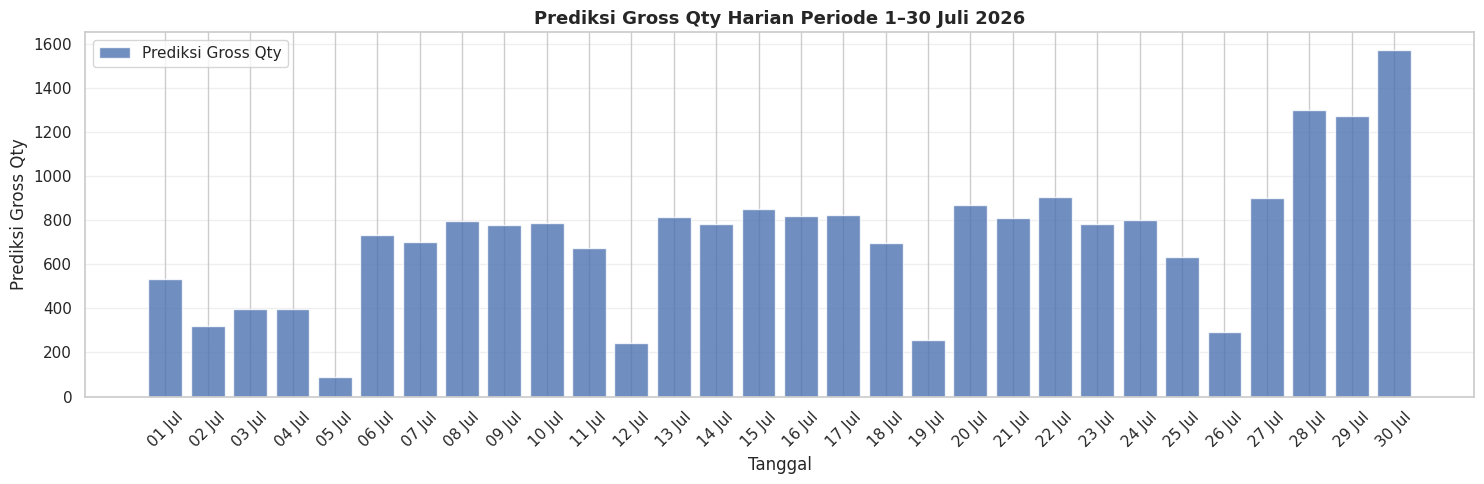

In [63]:
# ============================================================
# 7. VISUALISASI PREDIKSI HARIAN
# ============================================================

plt.figure(figsize=(15, 5))

plt.bar(
    forecast_df["Tanggal"],
    forecast_df["Prediksi_Gross_Qty"],
    label="Prediksi Gross Qty",
    alpha=0.8
)

plt.title(
    "Prediksi Gross Qty Harian Periode 1–30 Juli 2026",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel("Tanggal")
plt.ylabel("Prediksi Gross Qty")

plt.xticks(
    forecast_df["Tanggal"],
    forecast_df["Tanggal"].dt.strftime("%d %b"),
    rotation=45
)

plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

,Fitur,Importance
0,Day,0.16
1,Is_Weekend,0.13
2,Day_of_Week,0.12
3,Month,0.12
4,Lag_1,0.10
5,Lag_14,0.09
6,Lag_3,0.07
7,Rolling_Mean_7,0.06
8,Rolling_Mean_14,0.06
9,Lag_7,0.05


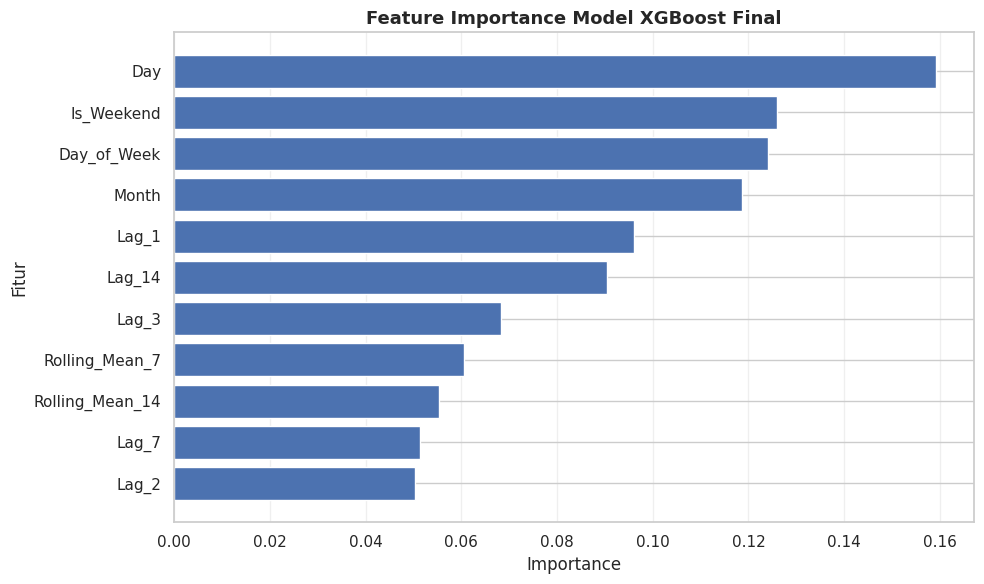

In [64]:
# ============================================================
# 9. FEATURE IMPORTANCE MODEL FINAL
# ============================================================

importance_df = pd.DataFrame({
    "Fitur": X_full.columns,
    "Importance": model_xgb_final.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

display(importance_df)

plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["Fitur"],
    importance_df["Importance"]
)

plt.title(
    "Feature Importance Model XGBoost Final",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel("Importance")
plt.ylabel("Fitur")
plt.gca().invert_yaxis()

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()